<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/01_ML_PLA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perceptron Learning Algorithm


---


This tutorial explores the concept of the perceptron. While the perceptron itself is relatively straightforward, it is not commonly used as a standalone method in modern machine learning. However, it serves as a foundational building block for more advanced machine learning models, such as neural networks, which have paved the way for the field of deep learning.

The Perceptron
--------------
The perceptron is a binary classifier that takes an input vector $\mathbf{x} = [x_1, x_2, \dotsc, x_n]^T$ and produces a binary prediction $y \in \{-1, +1\}$. It achieves this by computing a scalar value through the dot product of the input vector elements and learned weights $\mathbf{w} = [w_1, w_2, \dotsc, w_n]^T$, and then summing these products. This operation is represented as the vector dot product $\mathbf{w}^T \mathbf{x}$. Subsequently, the perceptron compares the scalar value $\mathbf{w}^T \mathbf{x}$ with a threshold $t$. If it's above the threshold, the perceptron predicts $y = +1$; otherwise, it predicts $y = -1$. This can be formulated as a linear predictor:

$$
y  = \begin{cases}
          +1, & \text{if} & \mathbf{w}^T \mathbf{x} \ge t \\
          -1, & \text{if} & \mathbf{w}^T \mathbf{x} < t
      \end{cases}
$$

Incorporating Bias
-------------------
To eliminate the threshold parameter, a common technique is to include it as a bias. By appending $x_0 = 1$ to the input $\mathbf{x}$, we have $\mathbf{x} = [x_0, x_1, x_2, \dotsc, x_n]^T$ and $\mathbf{w} = [w_0, w_1, w_2, \dotsc, w_n]^T$. The weight $w_0$ now represents the threshold ($w_0 = -t$), as $\mathbf{w}^T \mathbf{x} = \sum_{i=1}^n w_i x_i + w_0 x_0$ with $x_0 = 1$. The linear predictor becomes:

$$
y  = \begin{cases}
          +1, & \text{if} & \mathbf{w}^T \mathbf{x} \ge 0 \\
          -1, & \text{if} & \mathbf{w}^T \mathbf{x} < 0
      \end{cases} = \text{sign}(\mathbf{w}^T \mathbf{x})
$$

The perceptron architecture can be illustrated in the below figure:

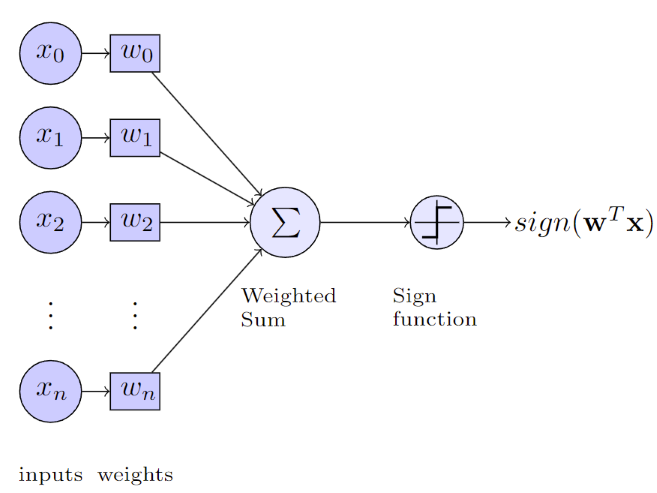


Learning Process
-----------------
The learning process of the perceptron involves iterative weight updates until a decision boundary is reached (in cases of linearly separable data). The initial weights can be set to a zero vector, i.e., $\mathbf{w} = \mathbf{0}$. The algorithm processes each data point $x_i$ and classifies it using the current weights as either $+1$ or $-1$ through $\text{sign}(\mathbf{w}^T \mathbf{x})$. If the classification is incorrect (i.e., $\text{sign}(\mathbf{w}^T \mathbf{x}) \ne y_i$), the weights are updated using $\mathbf{w} \leftarrow \mathbf{w} + y_i x_i$. The number of iterations can also be specified.

For deeper insight, this tutorial provides Python code (a widely used language in machine learning) to implement these algorithms, along with informative visualisations.



> The code in this tutorial is adopted from "Python Machine Learning," Sebastian Raschka, Packt Publishing, 2015 (page 25), with modifications.



# Iris dataset

In this tutorial, we will use the famous Iris flower dataset to assess the performance of the perceptron. The Iris flowers dataset, an iconic benchmark in the field, comprises an assortment of floral specimens. Within this dataset, each individual specimen is characterised by four distinct features: the length and width of both sepals and petals. A total of 50 samples from three unique Iris species - Versicolor, Virginica, and Setosa - contribute to this dataset, each adding their own unique traits and attributes to the mix. This array of diverse floral profiles forms the basis for our exploration into the capabilities of the perceptron model. Below is a picture of the the Iris flowers that we will deal with.

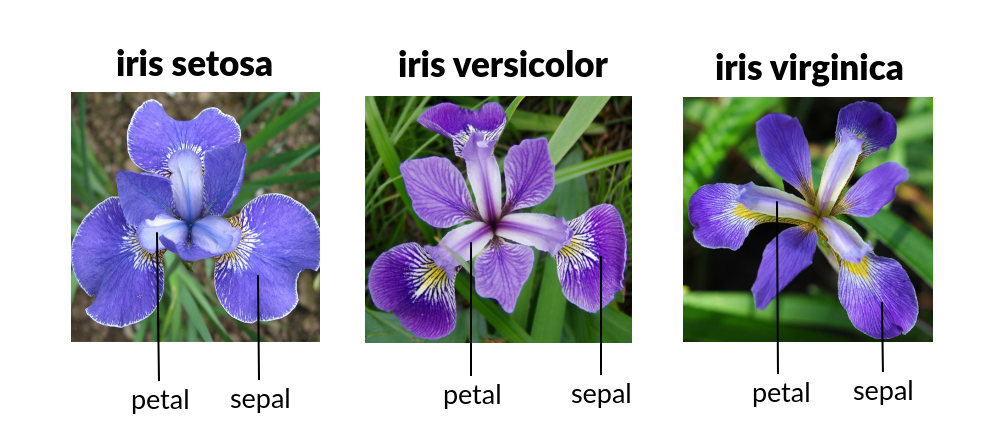

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pandas.plotting import scatter_matrix
import warnings
warnings.filterwarnings('ignore')

In [2]:
# We can use the sklearn package in order to import the data directly. Or you can dowload it as csv file and import it.
from sklearn.datasets import load_iris
iris = load_iris()

# This command generates a decsription of the dataset if you need more information
print(iris['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


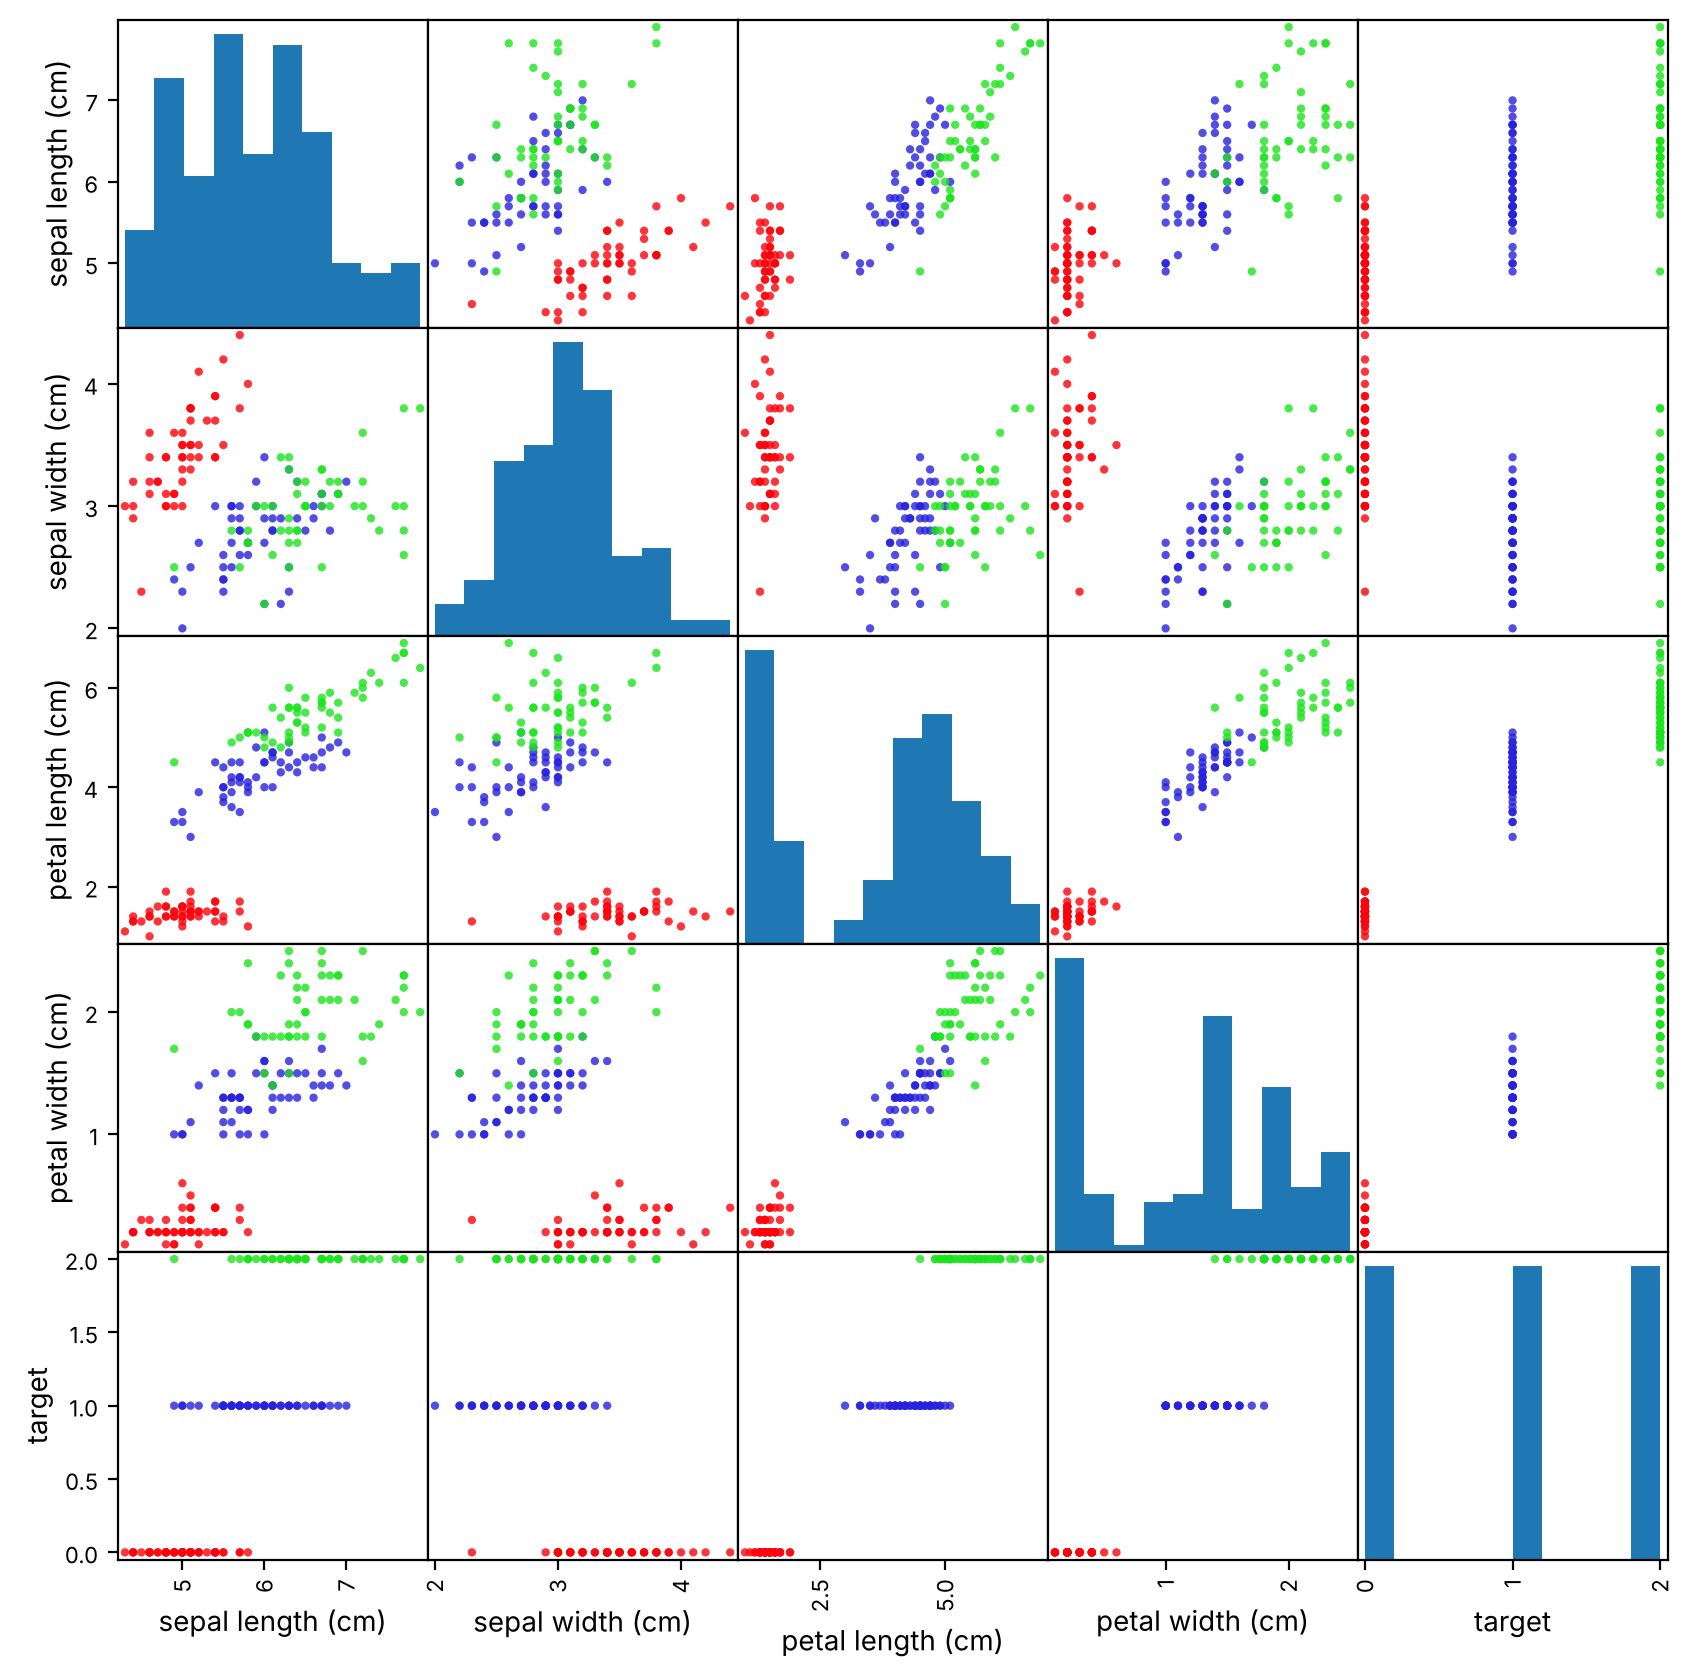

In [3]:
# You can visulaise the Iris data using the following cell for better understanding
# Note: the last column of this data represesent the labels, where 0 -> Setosa, 1 -> Versicolor, 2 -> Virginica

from pandas.plotting import scatter_matrix
import pandas as pd

iris_data = pd.DataFrame(data=iris['data'],columns=iris['feature_names'])

"""
Generate a scatter matrix plot to visualize the relationships between different features in the Iris dataset.
Each subplot in the matrix shows the scatter plot between two different features, while histograms on the diagonal
show the distribution of each individual feature. The color of points in the scatter plots is determined by the
corresponding class labels (Setosa, Versicolor, Virginica), where each class is assigned a distinct color.
The plot provides insights into possible patterns, correlations, and separations among features, aiding in data exploration.
"""

iris_data["target"] = iris['target']
color_dictionary = {1: "#FE010A", 2: "#2722DD", 3: "#1BE41D"}
colors = iris_data["target"].map(lambda x: color_dictionary.get(x + 1))
ax = scatter_matrix(iris_data, color=colors, alpha=0.8, figsize=(10, 10), diagonal='hist')

iris_data

#scroll down to see the plots

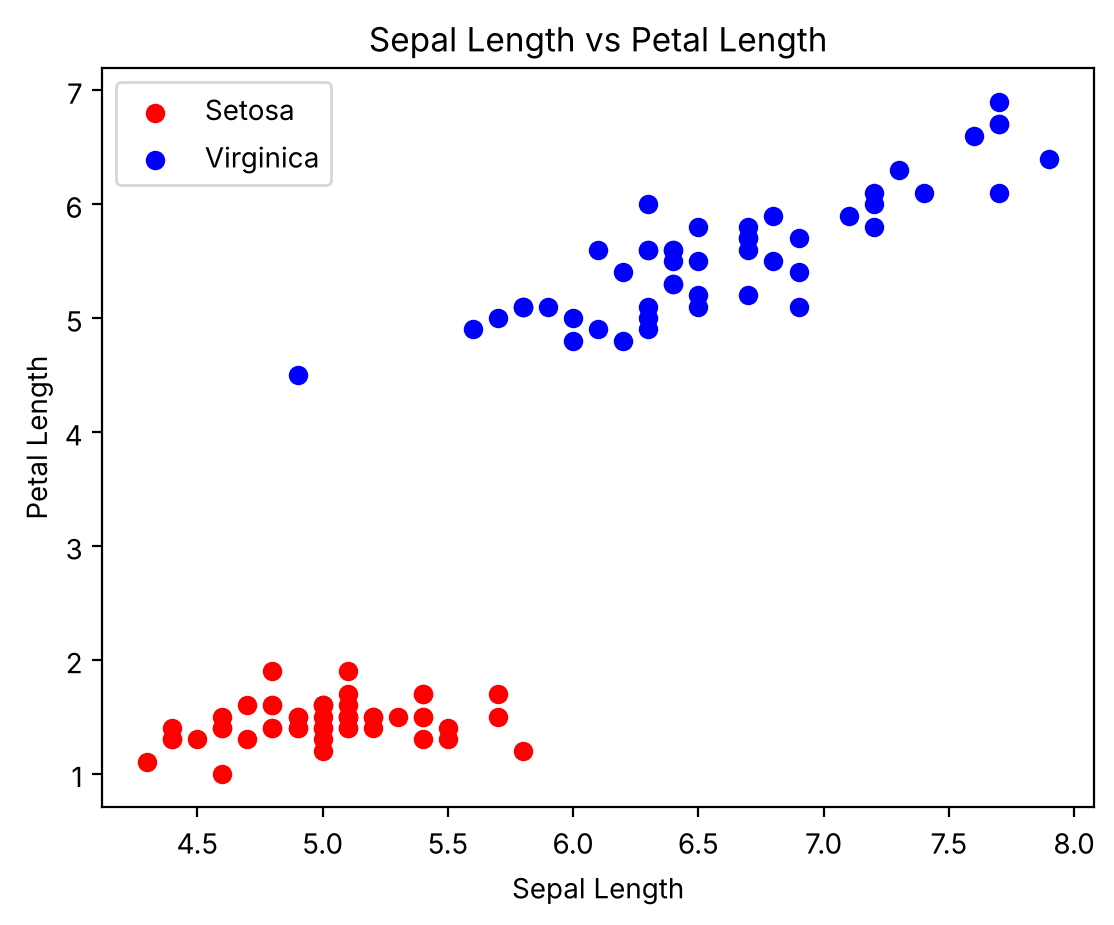

In [4]:
"""
We will use the perceptron as binary classifier, therefore we will choose two classes from the three. Let it be Setosa
and Virginica. Furthermore, for better data visualisation, we will consider two features; petal length and sepal length
this will make us see the features in 2D plot.
"""

# The following line of code will include the labels for Setosa and Virginica classes in one array and discard the Versicolor.
setosa_label = iris_data.iloc[0:50,4].values
virginica_label = iris_data.iloc[100:150,4].values
labels = np.concatenate((setosa_label,virginica_label))

"""
Note that from the original data Setosa is labelled as 0 and Virginica is labelled as 2. In order to match the labels
with our defined sign function for binary classification, we change the labels such as Setosa class has label -1 and
Virginica has a label 1 using the following code
"""
y = np.where(labels == 0, -1, 1)

# The following line of code will consider the two features (petal length and sepal length only) for the Setosa and Virginica
# classes and combine the features in one array.

X_setosa = iris_data.iloc[0:50, [0,2]]
X_virginica = iris_data.iloc[100:150, [0,2]]
X = np.concatenate((X_setosa,X_virginica))

# We can plot the features in 2D plot such that the sepal length feature is represented by x-axis
# and petal length  is represented by y-axis

plt.scatter(X[:50,0],X[:50,1],color='red',marker='o',label='Setosa')
plt.scatter(X[50:100,0],X[50:100,1],color='blue',marker='o',label='Virginica')
plt.title("Sepal Length vs Petal Length")
plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')
plt.legend(loc='upper left')
plt.show()

# PLA code

Having prepared our data, we are now ready to take a look at our first learning algorithm - PLA. The PLA is an iterative algorithm which iterates over each data points from the dataset.

Initial weights of the perceptron can be set to a vector of zeros, i.e. $\mathbf{w} = \mathbf{0}$. PLA then takes each data point $x_i$ and classifies it using the current perceptron weights as either $+1$ or $-1$ using $sign(\mathbf{w}^T \mathbf{x})$. The perceptron update rule is given as $\mathbf{w} \leftarrow \mathbf{w} + y_i x_i$. Note that the update is done only if the predicted label is incorrect and the weights are updated in the opposite direction to the prediction i.e., the predicted label was $+1$ while the true one was $-1$ and vice versa. In this way the error should decrease in the next iteration. After the update of the  weights, we iterate through the rest of the points and update the weights again if necessary. If the dataset is separable i.e. all data points can be classified correctly, then the algorithm will eventually iterate through all the  data points without any misclassification.

In [5]:
def predict(W, X):
        """ Return class label after each setp """
        return np.where(net_input(W, X) >= 0.0, 1, -1)

In [6]:
def net_input(W, X):
        """ Calculate net input """
        return np.dot(X, W[1:]) + W[0]

In [7]:
def plot_boundary(W, X):
    """Function to plot the boundary defined by the weights. Given equation."""
    """w0 + w1*x1 + w2*x2 = 0, used to generate the line."""

    # Calculate the slope and y-intercept of the boundary line
    slope = -W[1] / W[2]
    intercept = -W[0] / W[2]

    # Get the minimum and maximum x values from the dataset
    x_min = np.min(X[:, 0])
    x_max = np.max(X[:, 0])

    # Generate points for the boundary line to cover the whole plot
    x_vals = np.array([x_min, x_max])
    y_vals = slope * x_vals + intercept

    # This part here define the x-axis and y-axis style according to the data we are using
    plt.figure(figsize=(5, 4))
    plt.scatter(X[:50, 0], X[:50, 1], color='red', marker='o', label='Setosa')
    plt.scatter(X[50:100, 0], X[50:100, 1], color='blue', marker='o', label='Virginica')
    plt.title("Sepal Length vs Petal Length")
    plt.xlabel('Sepal Length')
    plt.ylabel('Petal Length')
    plt.legend(loc='upper left')

    # Plot the line using the calculated points
    plt.plot(x_vals, y_vals, 'black')

    plt.show()

In [8]:
def plot_errors(error):
    """ Function to plot number of misclassified samples """
    plt.plot(range(1, len(error) + 1), error,marker='o')
    plt.xlabel('Iterations')
    plt.ylabel('Number of misclassifications')
    plt.show()

In [9]:
def fit(n_iter, X, y):
        W = np.zeros(1 + X.shape[1])
        errors_ = []
        for i in range(n_iter):
            for j, (xi, target) in enumerate(zip(X,y)):
         #     update = target - predict(W, xi)
         #     W += 0.5*update*np.append(1,xi)
              if predict(W, xi) != target:
                  W = W + target * np.append(1,xi)
            # errors on whole dataset
            errors = 0
            for j, (xi, target) in enumerate(zip(X, y)):
                if predict(W, xi) != target:
                    errors += 1
            # -------------------------------------------
            errors_.append(errors)
            i += 1
            print ("Iteration: ", i)
            print("Weights: ", W)
            print("Misclassified Samples: ", errors)
            plot_boundary(W,X) # When weights are updated we plot the boundary
        plot_errors(errors_)

Iteration:  1
Weights:  [0.  1.2 4.6]
Misclassified Samples:  50


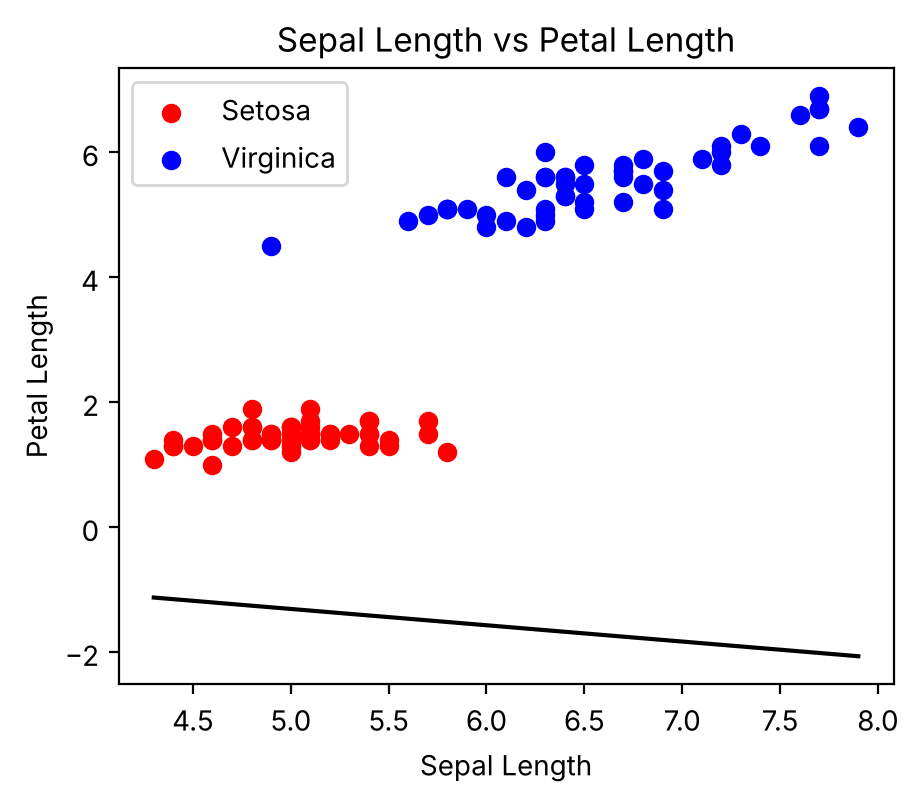

Iteration:  2
Weights:  [0.  2.4 9.2]
Misclassified Samples:  50


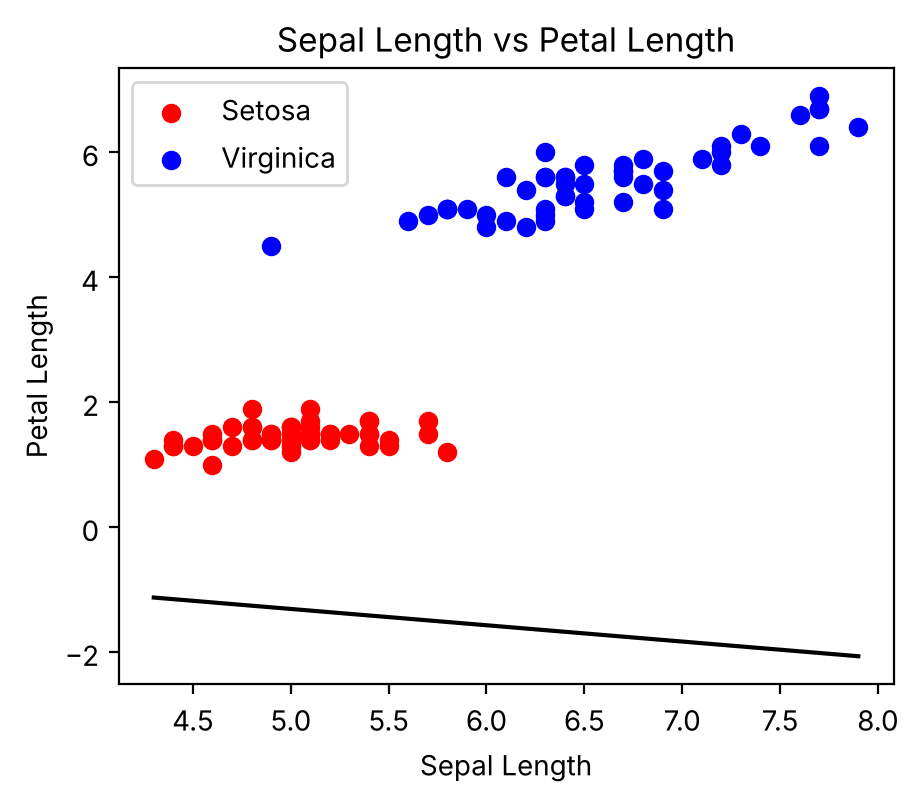

Iteration:  3
Weights:  [-1.  -1.2 11.9]
Misclassified Samples:  50


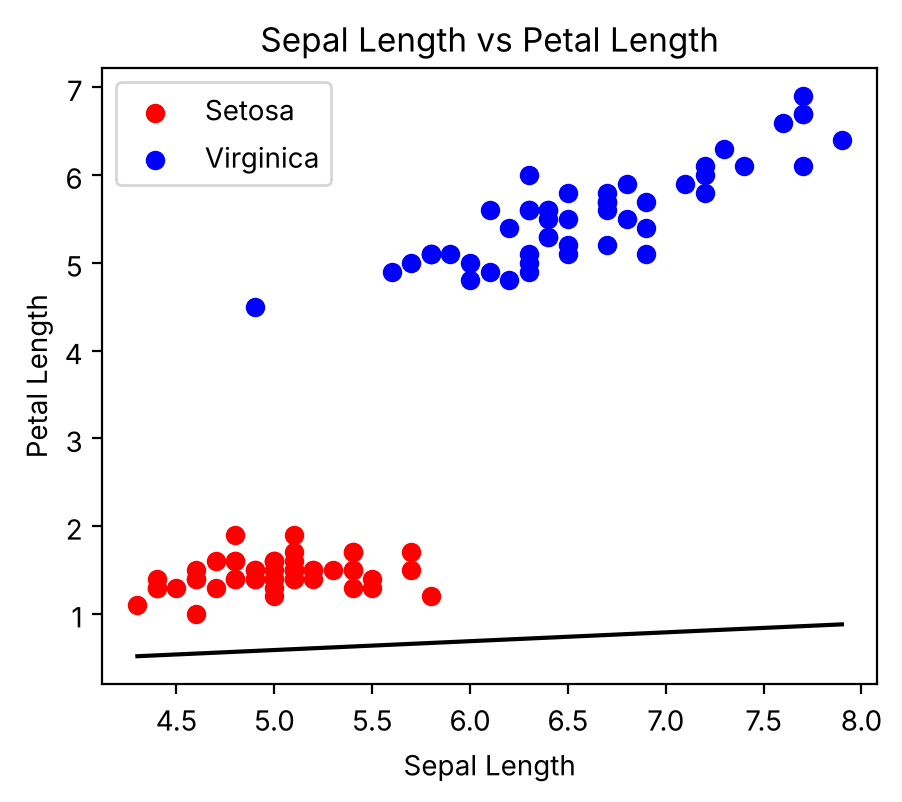

Iteration:  4
Weights:  [-2.  -6.3 10.5]
Misclassified Samples:  0


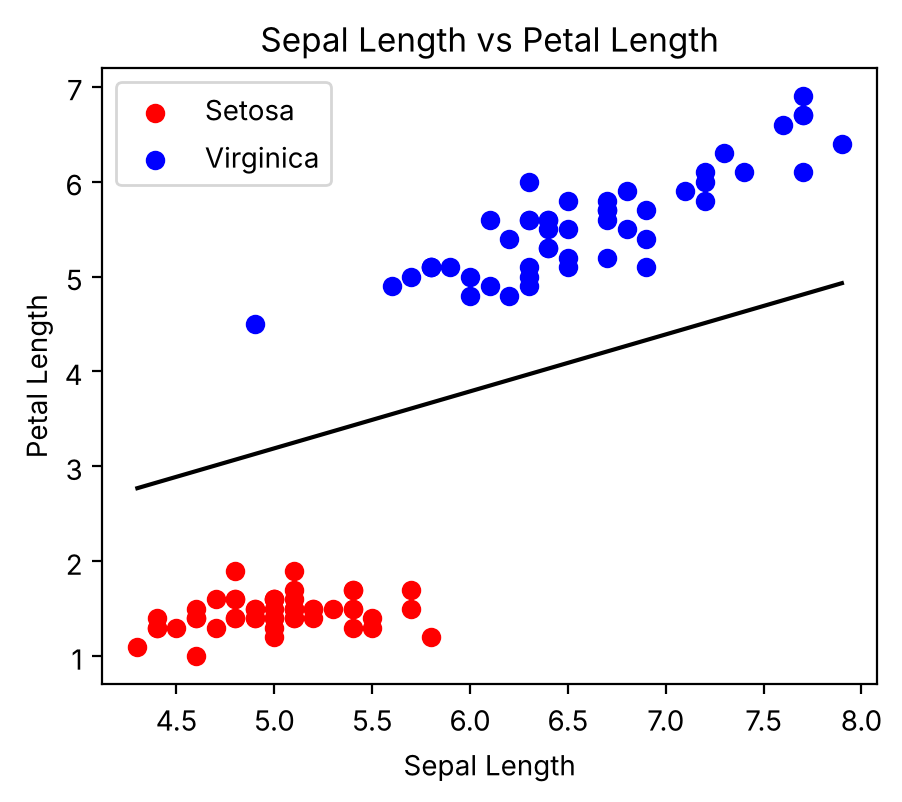

Iteration:  5
Weights:  [-2.  -6.3 10.5]
Misclassified Samples:  0


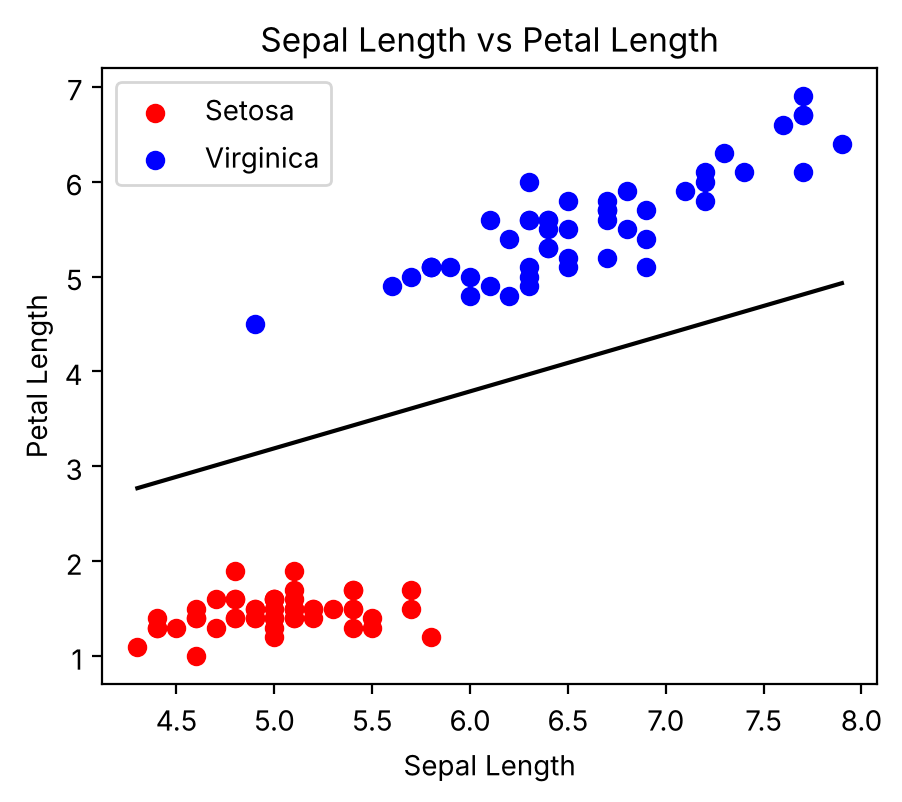

Iteration:  6
Weights:  [-2.  -6.3 10.5]
Misclassified Samples:  0


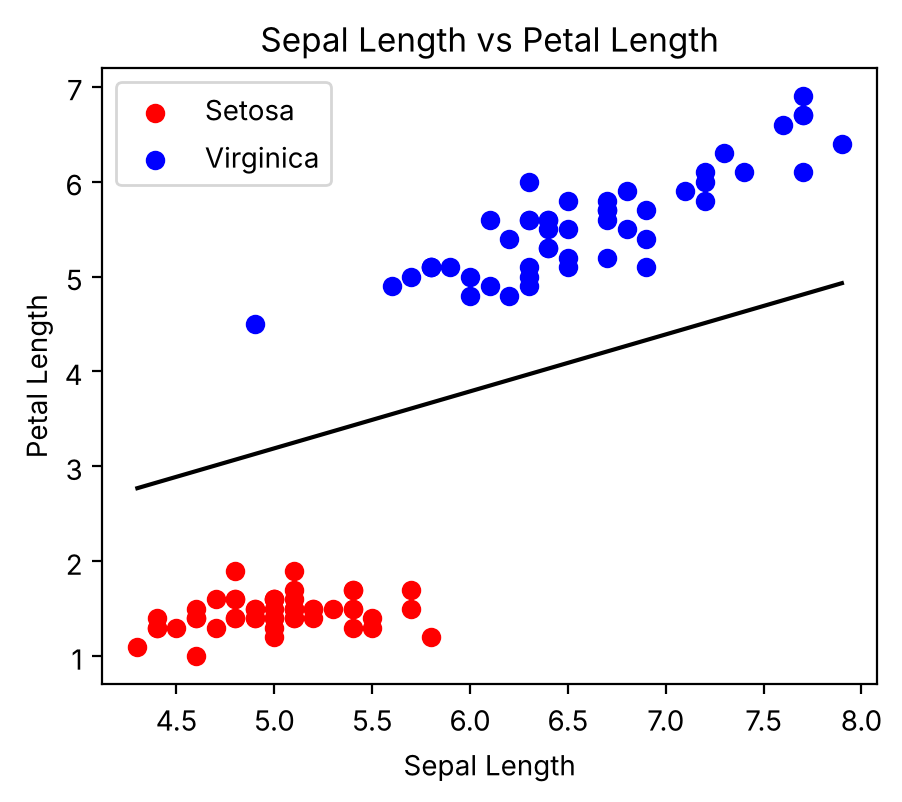

Iteration:  7
Weights:  [-2.  -6.3 10.5]
Misclassified Samples:  0


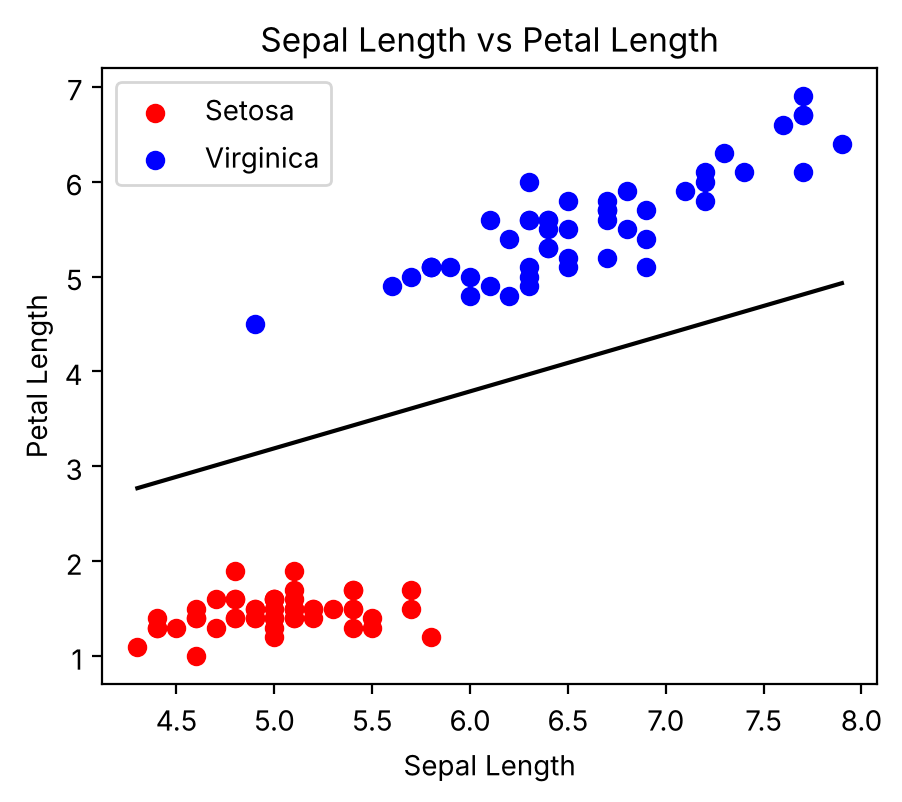

Iteration:  8
Weights:  [-2.  -6.3 10.5]
Misclassified Samples:  0


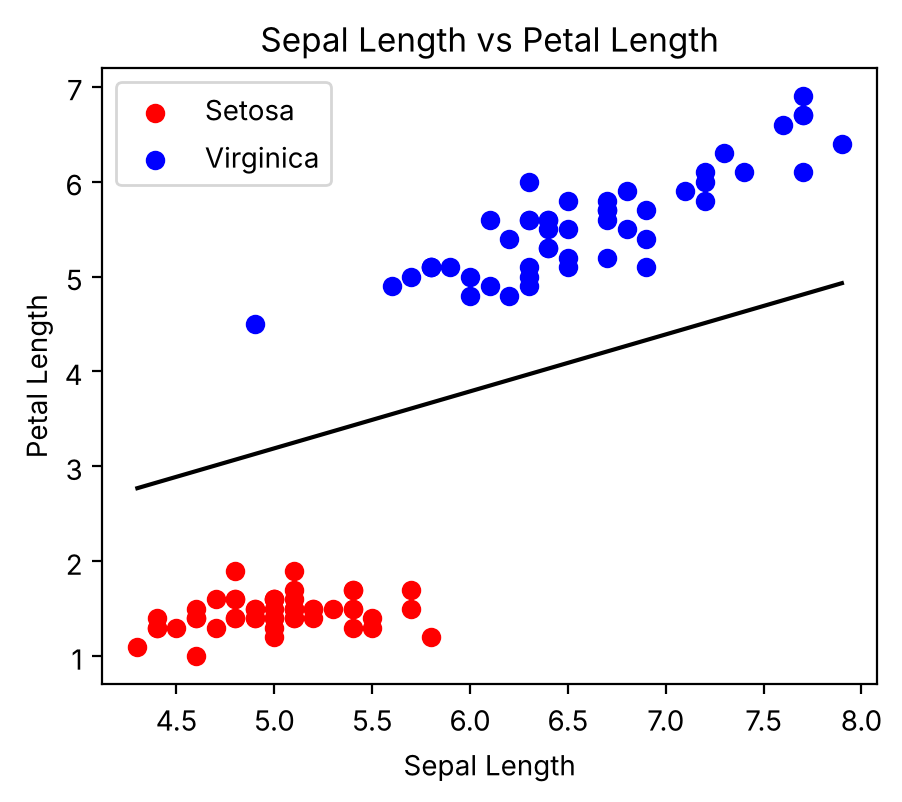

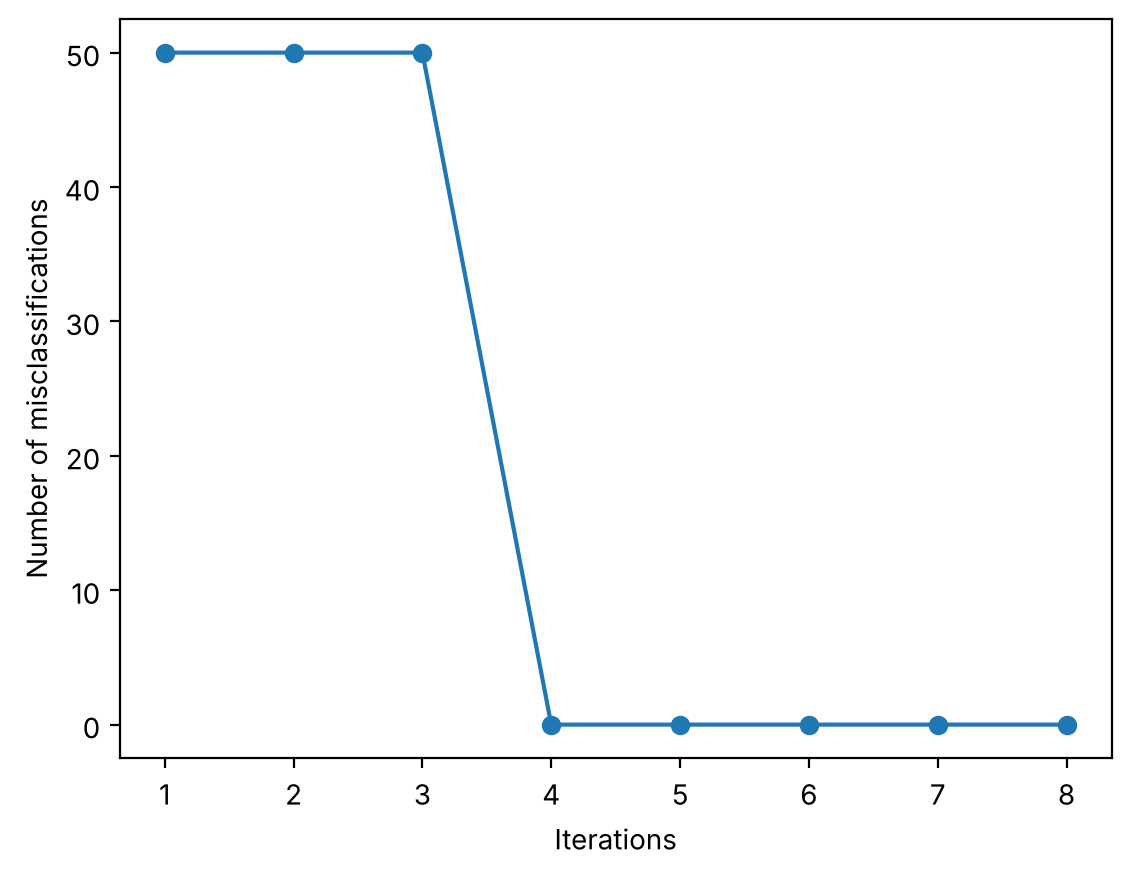

In [10]:
n_iter=8
fit(n_iter, X, y)

## Task 1 [40 marks]

**Perceptron Algorithm for Setosa vs. Versicolor Classification**

In this task, we will replicate the previous steps of the tutorial to perform binary classification between the Setosa and Versicolor classes using the same two features, namely petal length and sepal length. Your report should include the following components:

### Steps to Follow:

1. **Data Selection:**
   - Choose the Setosa and Versicolor classes from the Iris dataset.
   - Select the petal length and sepal length features as done in the previous task.

2. **Data Visualisation:**
   - Generate a plot that clearly demonstrates the linear separability of the Setosa and Versicolor classes based on the selected features.

3. **Perceptron Algorithm Execution:**
   - Implement the perceptron algorithm for the Setosa vs. Versicolor classification task.
   - Specify the number of iterations to perform during the algorithm execution.

4. **Misclassification Analysis:**
   - Create a plot illustrating the change in misclassified samples across the iterations of the perceptron algorithm.

5. **Final Weight Reporting:**
   - Report the final weight values obtained as a result of the perceptron algorithm.

6. **Code Showcase:**
   - Include the code segments that you modified or added for each step of the process.
   - Discuss the specific adaptations you made to the code to suit the Setosa vs. Versicolor classification.


### Task 1 – Step 1: Data selection

Setosa is rows 0–49 and Versicolor is rows 50–99 of the Iris data, so the two classes are simply the first 100 rows.
The features are the same as in the tutorial: column 0 (sepal length) and column 2 (petal length).
Setosa (original label 0) is mapped to **-1** and Versicolor (original label 1) to **+1** so the labels match the `sign` function.

In [11]:
# Step 1: select Setosa (rows 0-49) and Versicolor (rows 50-99)
setosa_label     = iris_data.iloc[0:50, 4].values
versicolor_label = iris_data.iloc[50:100, 4].values
labels_t1 = np.concatenate((setosa_label, versicolor_label))

# Setosa (0) -> -1, Versicolor (1) -> +1
y_t1 = np.where(labels_t1 == 0, -1, 1)

# Features: sepal length (col 0) and petal length (col 2)
X_setosa     = iris_data.iloc[0:50, [0, 2]]
X_versicolor = iris_data.iloc[50:100, [0, 2]]
X_t1 = np.concatenate((X_setosa, X_versicolor))

print("X shape:", X_t1.shape, "| y shape:", y_t1.shape)
print("Class counts:", dict(zip(*np.unique(y_t1, return_counts=True))))

X shape: (100, 2) | y shape: (100,)
Class counts: {np.int64(-1): np.int64(50), np.int64(1): np.int64(50)}


### Task 1 – Step 2: Data visualisation

The scatter plot shows the Setosa points sit in a clearly separate region (much smaller petal length) from the Versicolor points, so a single straight line can separate them – the classes are **linearly separable**.

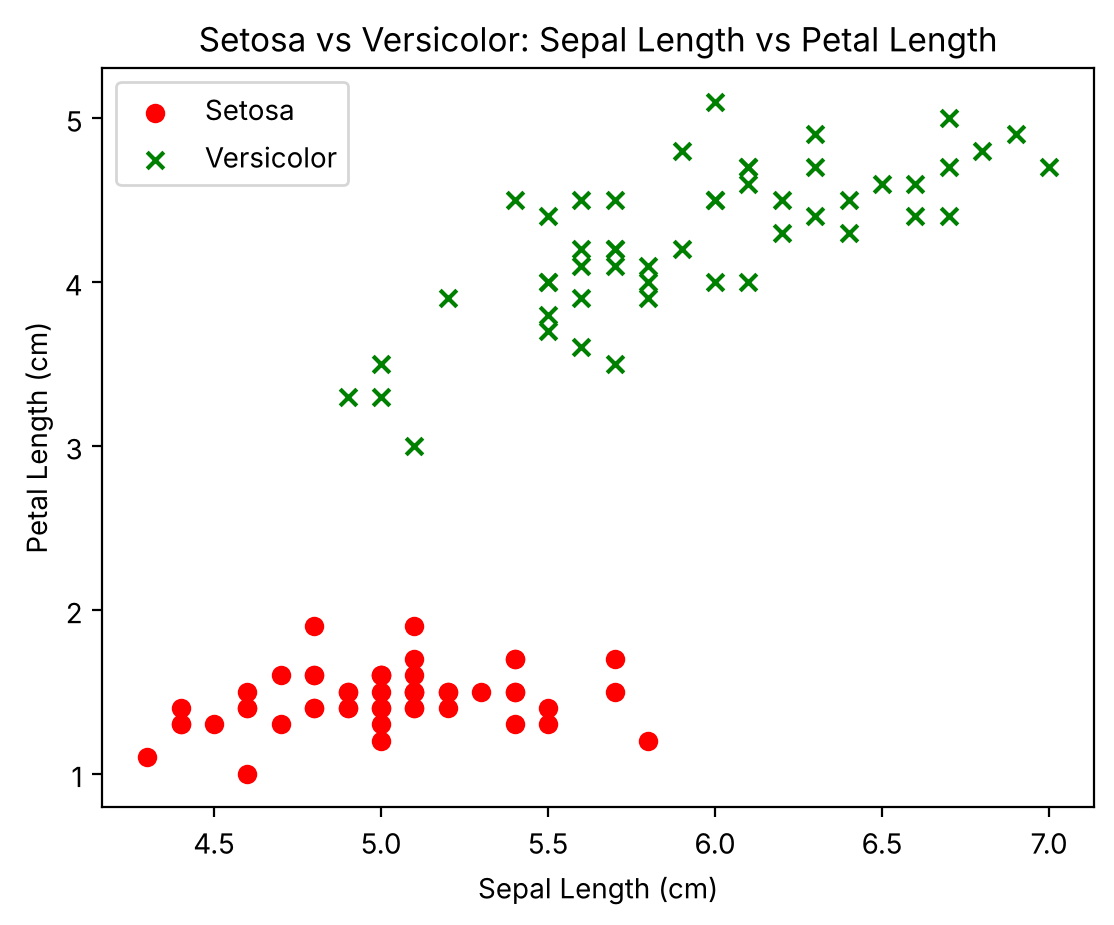

In [12]:
# Step 2: visualise the two classes
plt.scatter(X_t1[:50, 0], X_t1[:50, 1], color='red',   marker='o', label='Setosa')
plt.scatter(X_t1[50:, 0], X_t1[50:, 1], color='green', marker='x', label='Versicolor')
plt.title("Setosa vs Versicolor: Sepal Length vs Petal Length")
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.legend(loc='upper left')
plt.show()

### Task 1 – Step 3: Perceptron execution

The original `plot_boundary` hard-codes the label `'Virginica'` and the colour scheme, so it is generalised to take the class names and a title.
`fit` is adapted the same way (class names passed through) and now also **returns** the final weights and the error history so they can be reported.
The learning rule itself is unchanged: `W ← W + y_i·[1, x_i]` whenever a point is misclassified.

**Number of iterations: 10** (the data are separable, so convergence is expected well before this).

Iteration: 1 | Weights: [0.  1.9 3.3] | Misclassified: 50


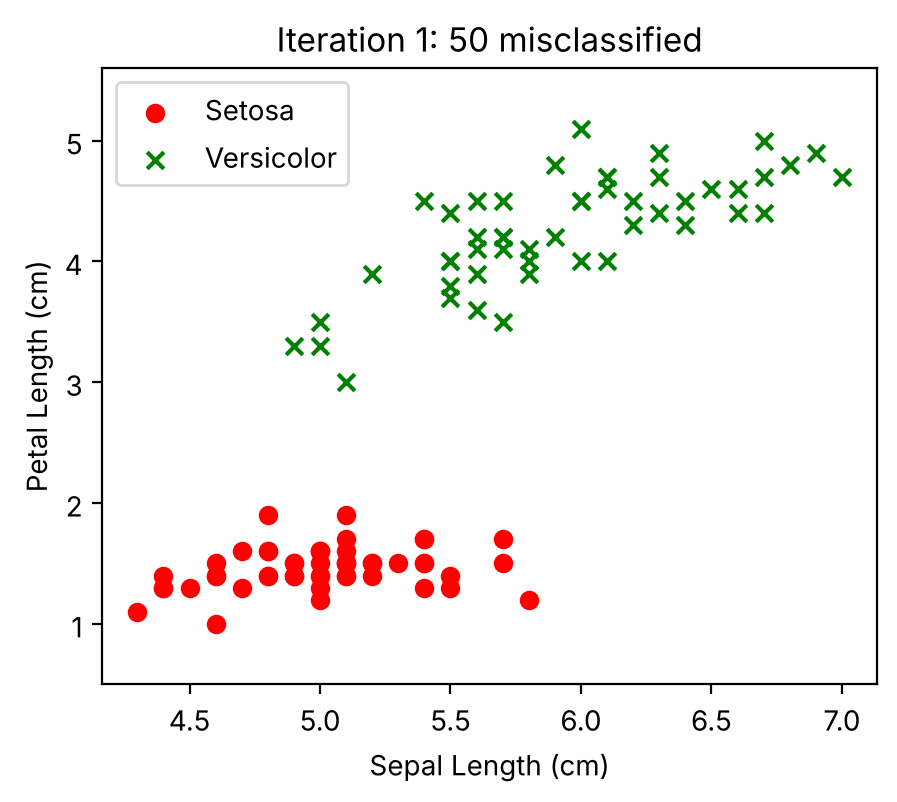

Iteration: 2 | Weights: [0.  3.8 6.6] | Misclassified: 50


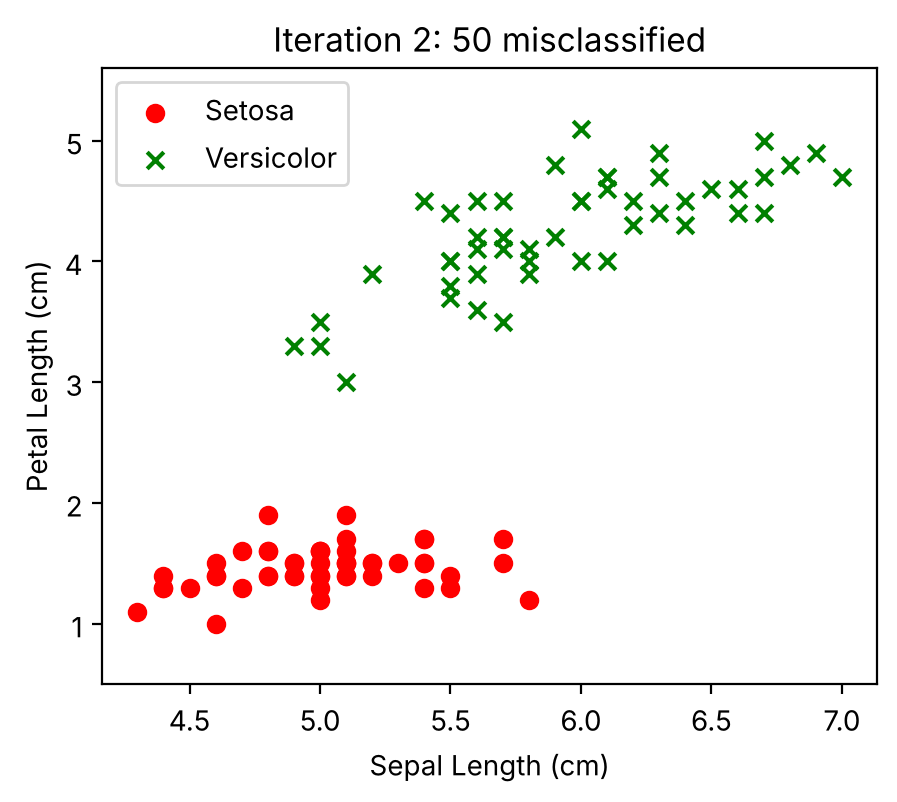

Iteration: 3 | Weights: [-1.   1.1  8.4] | Misclassified: 50


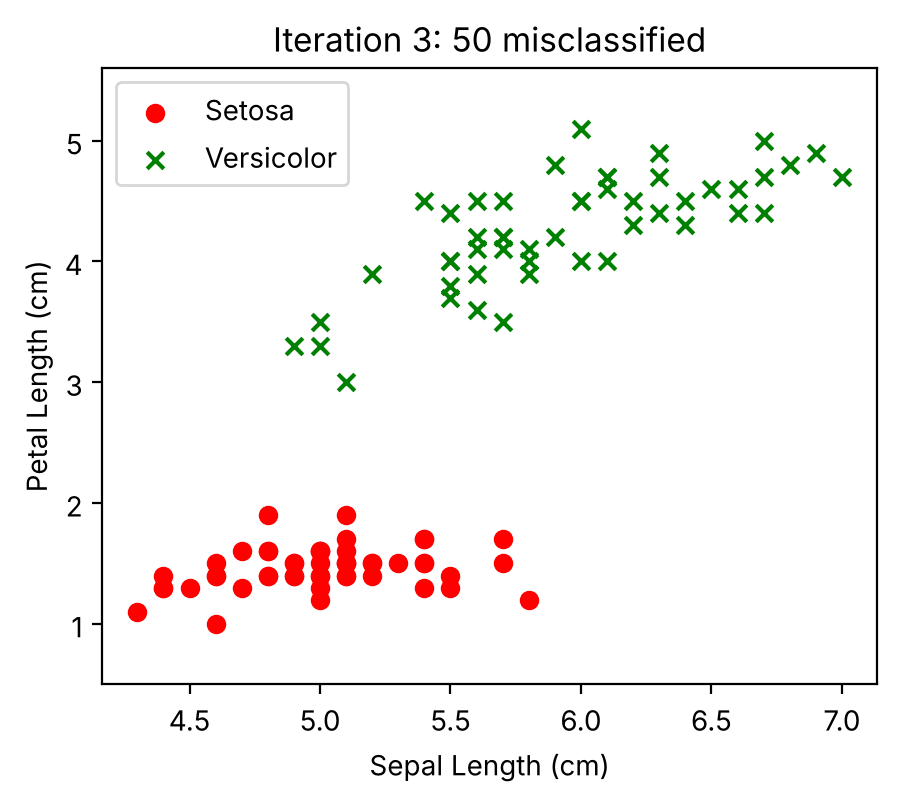

Iteration: 4 | Weights: [-1.   1.7 10.5] | Misclassified: 50


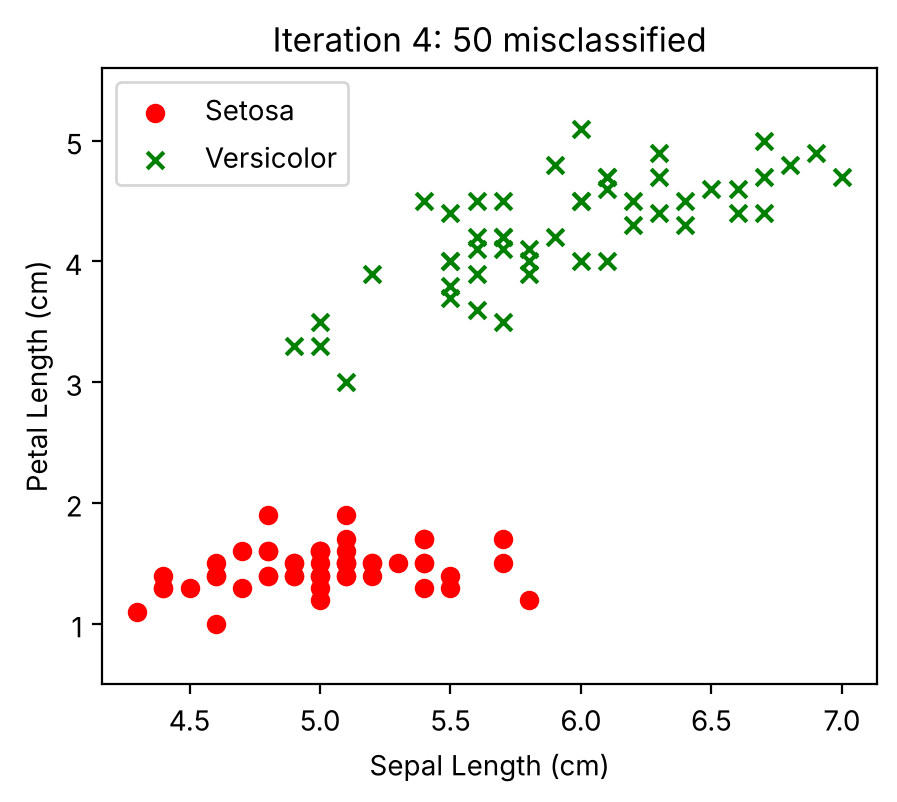

Iteration: 5 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


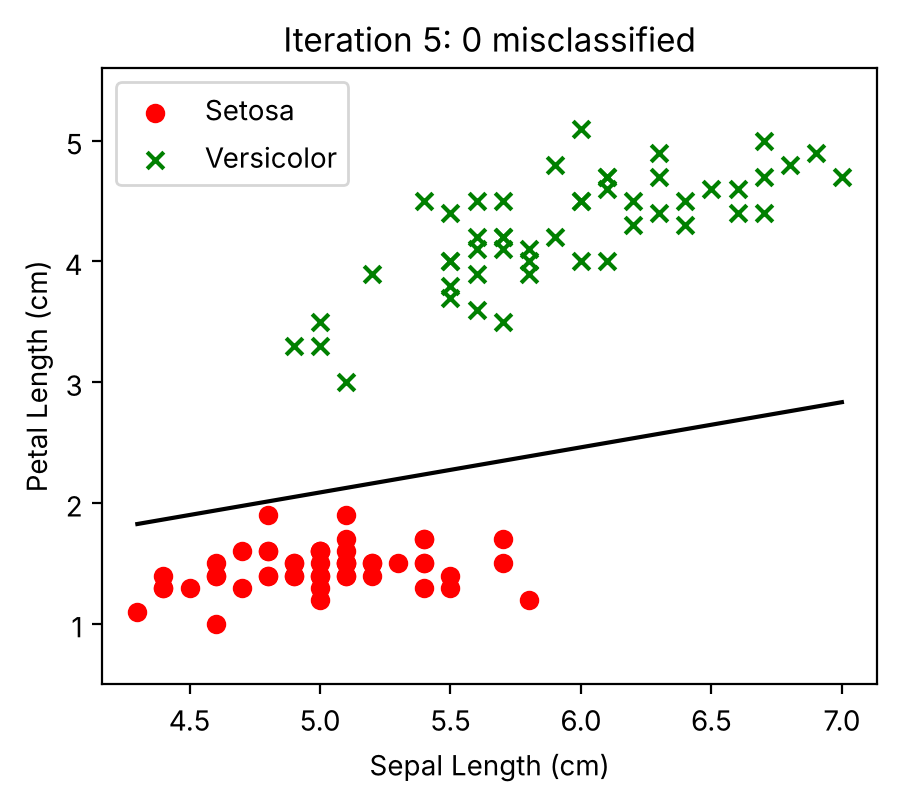

Iteration: 6 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


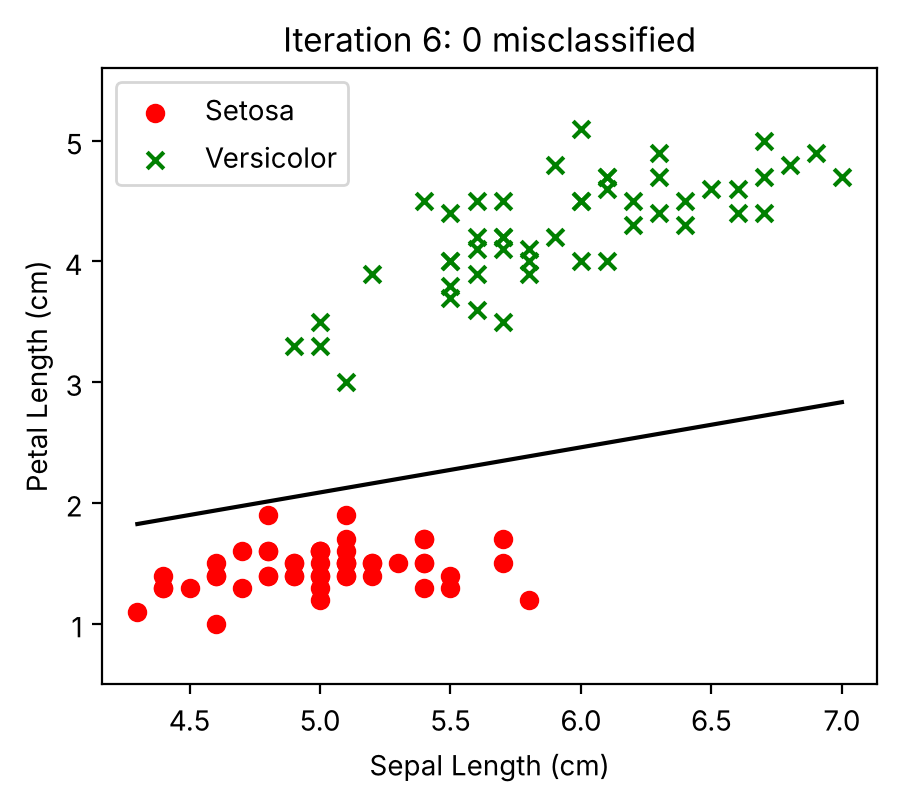

Iteration: 7 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


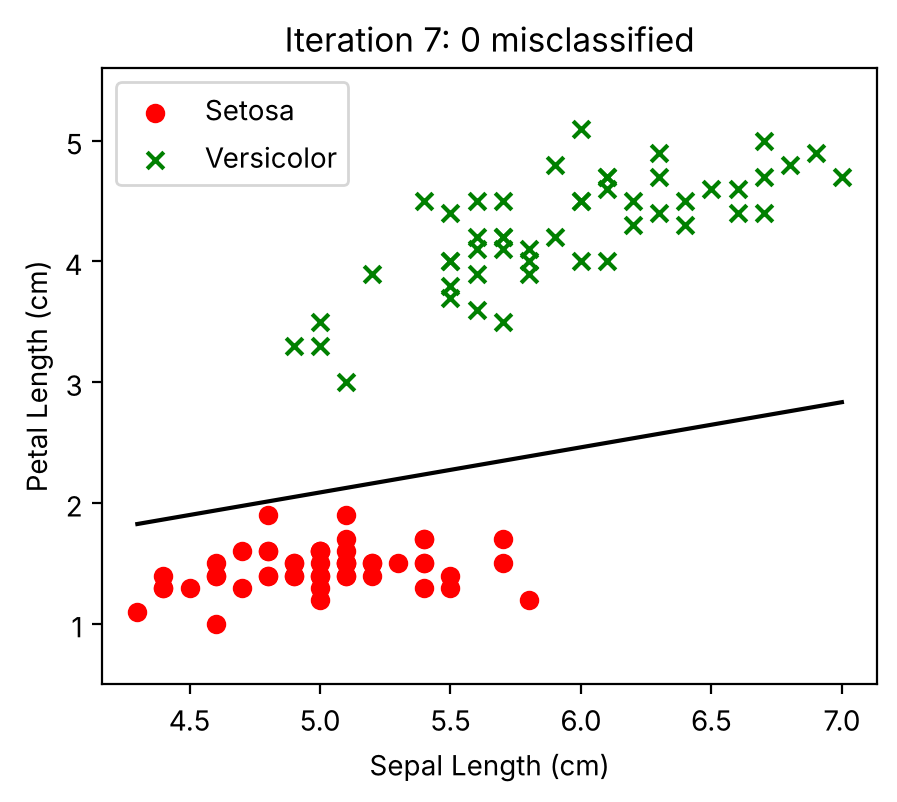

Iteration: 8 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


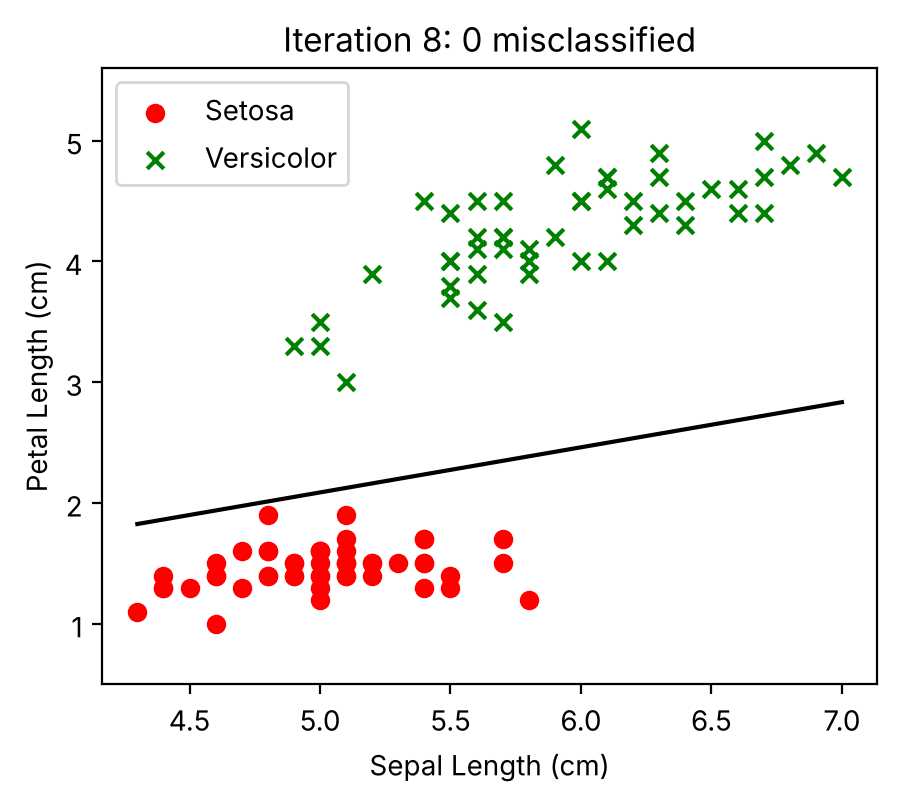

Iteration: 9 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


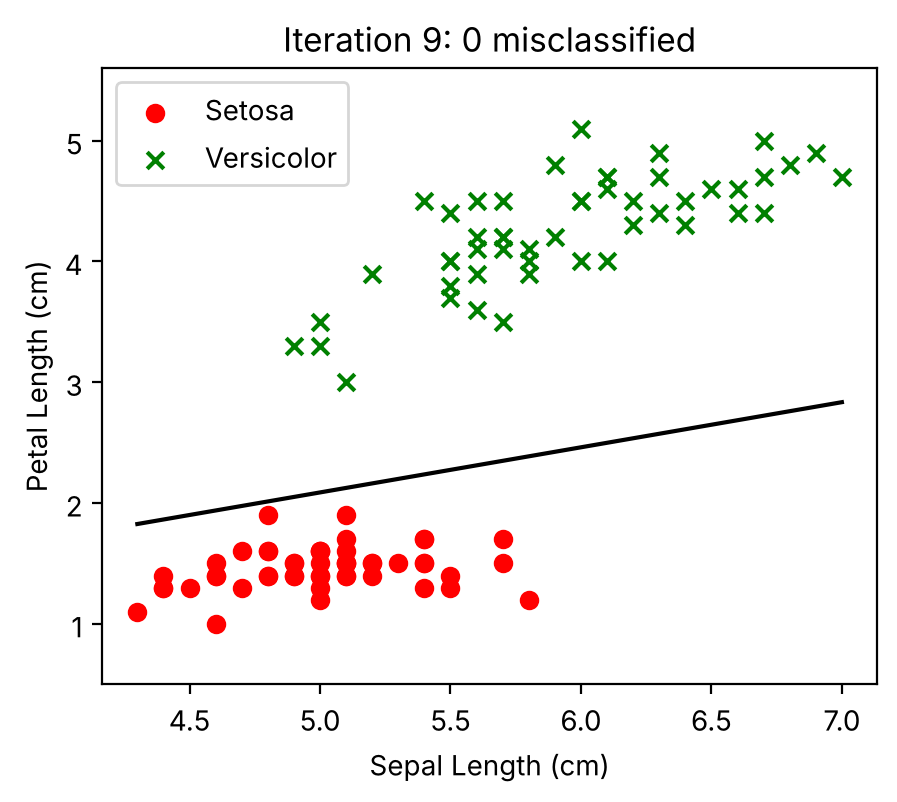

Iteration: 10 | Weights: [-2.  -3.4  9.1] | Misclassified: 0


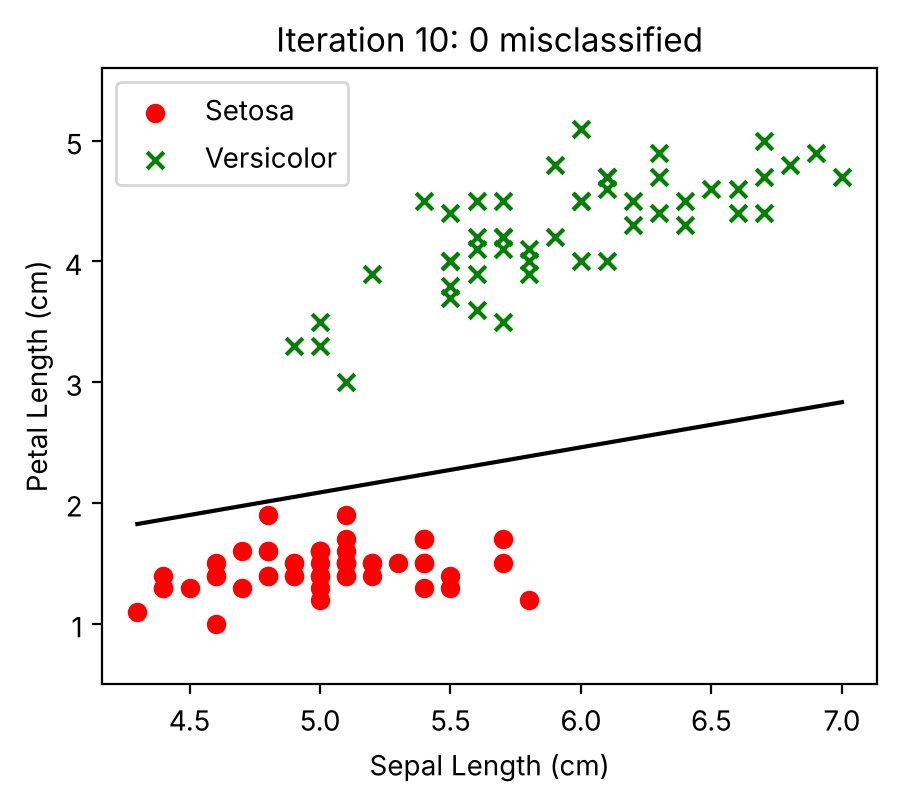

In [13]:
def plot_boundary_general(W, X, names=('Class -1', 'Class +1'), colors=('red', 'green'), title=None):
    """Plot data (first half = class -1, second half = class +1) and the line w0 + w1*x1 + w2*x2 = 0."""
    n = len(X) // 2
    plt.figure(figsize=(5, 4))
    plt.scatter(X[:n, 0], X[:n, 1], color=colors[0], marker='o', label=names[0])
    plt.scatter(X[n:, 0], X[n:, 1], color=colors[1], marker='x', label=names[1])

    x_vals = np.array([np.min(X[:, 0]), np.max(X[:, 0])])
    if W[2] != 0:                       # normal case: y = -(w0 + w1*x)/w2
        y_vals = -(W[0] + W[1] * x_vals) / W[2]
        plt.plot(x_vals, y_vals, 'black')
    elif W[1] != 0:                     # vertical line x = -w0/w1
        plt.axvline(-W[0] / W[1], color='black')

    plt.ylim(np.min(X[:, 1]) - 0.5, np.max(X[:, 1]) + 0.5)
    plt.title(title if title else "Sepal Length vs Petal Length")
    plt.xlabel('Sepal Length (cm)')
    plt.ylabel('Petal Length (cm)')
    plt.legend(loc='upper left')
    plt.show()


def fit_t1(n_iter, X, y, names):
    W = np.zeros(1 + X.shape[1])
    errors_ = []
    for i in range(n_iter):
        for xi, target in zip(X, y):
            if predict(W, xi) != target:
                W = W + target * np.append(1, xi)      # perceptron update
        errors = int(np.sum(predict(W, X) != y))        # errors on whole dataset
        errors_.append(errors)
        print("Iteration:", i + 1, "| Weights:", W, "| Misclassified:", errors)
        plot_boundary_general(W, X, names=names, title=f"Iteration {i + 1}: {errors} misclassified")
    return W, errors_


n_iter_t1 = 10
W_t1, errors_t1 = fit_t1(n_iter_t1, X_t1, y_t1, names=('Setosa', 'Versicolor'))

### Task 1 – Step 4: Misclassification analysis

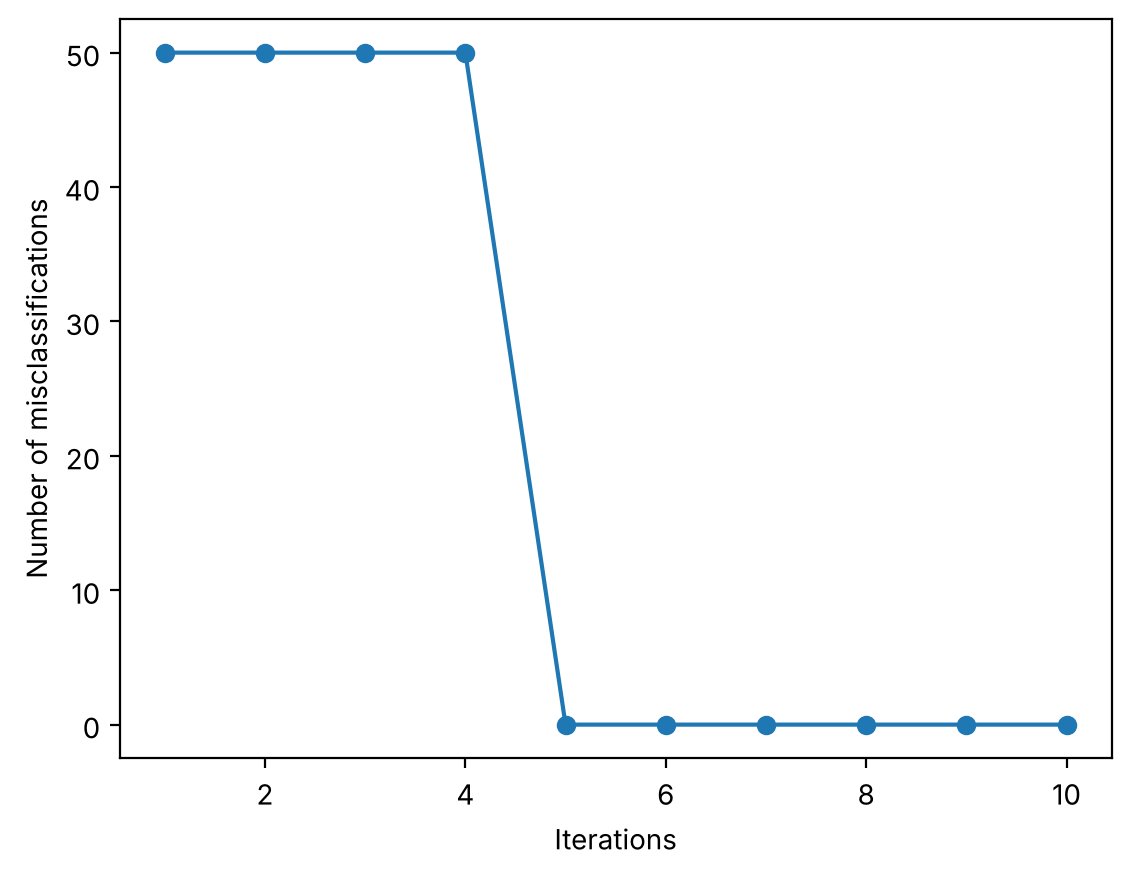

Converged (0 misclassifications) at iteration: 5


In [14]:
# Step 4: misclassifications per iteration
plot_errors(errors_t1)
first_zero = next((i + 1 for i, e in enumerate(errors_t1) if e == 0), None)
print("Converged (0 misclassifications) at iteration:", first_zero)

### Task 1 – Step 5: Final weights

In [15]:
# Step 5: final weights
print("Final weights  W = [w0, w1, w2] =", W_t1)
print(f"Decision boundary: {W_t1[0]:.2f} + ({W_t1[1]:.2f})*sepal_length + ({W_t1[2]:.2f})*petal_length = 0")
print("Training accuracy:", np.mean(predict(W_t1, X_t1) == y_t1) * 100, "%")

Final weights  W = [w0, w1, w2] = [-2.  -3.4  9.1]
Decision boundary: -2.00 + (-3.40)*sepal_length + (9.10)*petal_length = 0
Training accuracy: 100.0 %


### Task 1 – Step 6: Summary of code adaptations

| Step | Tutorial (Setosa vs Virginica) | Task 1 (Setosa vs Versicolor) | Why |
|---|---|---|---|
| Data selection | Rows `0:50` and `100:150` | Rows `0:50` and `50:100` | Versicolor occupies rows 50–99 |
| Labels | `np.where(labels == 0, -1, 1)` | Same mapping, now Versicolor (1) → +1 | Keeps Setosa as -1 to match `sign` |
| Plotting | Legend hard-coded to 'Virginica' | `plot_boundary_general` takes class names, guards against `w2 = 0` | Correct legend; avoids division by zero |
| `fit` | Returned nothing | `fit_t1` returns `W` and error list | Needed to report final weights and plot errors |
| Iterations | 8 | 10 | Enough for convergence |

**Result:** the perceptron reaches **0 misclassifications at iteration 5** and the final weights are **W = [-2.0, -3.4, 9.1]**, i.e. the boundary is −2 − 3.4·(sepal length) + 9.1·(petal length) = 0. Because the two classes are linearly separable, the Perceptron Convergence Theorem guarantees PLA stops making updates once a separating line is found, which is why the weights stay constant from iteration 5 onwards.

# Pocket Algorithm for perceptron

The Pocket Algorithm is an advanced version of the Perceptron algorithm designed to handle scenarios where data is not linearly separable and requires classification with minimal error. While the Perceptron focuses on linear classification, the Pocket Algorithm extends this approach to find a hyperplane that best separates the data while minimizing misclassification errors.

The key features of the Pocket Algorithm include:

- Unlike the Perceptron, which updates weights for each misclassification, the Pocket Algorithm maintains a "pocket" or memory of the best-performing weights encountered during training.
- This memory allows the algorithm to converge to a solution that might not be optimal for a linearly separable dataset but works better overall for non-linearly separable data.

### Suggested algorithm Steps:

1. **Initialization:**
   - Initialize the weight vector `W` randomly or to zeros.
   - Initialize the "pocket" weight vector `W_pocket` to zeros.

2. **Iteration:**
   - For each data point `x_i` in the training dataset:
     - Calculate the activation value `a = W^T * x_i`.
     - Predict the class label using the sign function: `y_pred = sign(a)`.
     - Compare the predicted label `y_pred` with the true label `y_i`.
     - If the prediction is incorrect:
       - Update the current weight vector `W` using the perceptron update rule.
       - Calculate the misclassification error on the entire dataset using the current `W`.
       - If the error is lower than the best error encountered so far (stored in `W_pocket`), update `W_pocket` with the current `W`.

3. **Termination:**
   - The algorithm continues iterating through the dataset until a predetermined number of iterations is reached or until the desired accuracy is achieved.

4. **Final Output:**
   - The final weight vector `W_pocket` represents the best-performing weights encountered during the iterations.
   - This weight vector can be used for making predictions on new, unseen data.

By "remembering" the best weight vector encountered during training, the Pocket Algorithm is effective for datasets that aren't linearly separable.

## Task 2 [60 marks]

Consider the Versicolor and Virginica classes using the same features (petal length and sepal length) as before. Unlike previous cases, these classes are not linearly separable. The perceptron classifier cannot effectively separate the classes using a single line as seen previously. In this analysis, we will:

1. **Plot Non-Linear Separability:**
   - Begin by visualizing the classes to showcase that they are not linearly separable using the selected features.

2. **Pocket Algorithm Implementation:**
   - Revise the PLA code to transform it into the Pocket Algorithm.
   - The Pocket Algorithm will help us find the best weights that result in minimal misclassification errors.

3. **Running the Pocket Algorithm:**
   - Execute the Pocket Algorithm for a larger number of iterations (e.g., 100) to effectively address the non-linear separability.
   - During these iterations, observe how the decision boundary evolves as the weights are updated.

4. **Plotting Misclassification Evolution:**
   - Create a plot illustrating how the number of misclassified samples changes with each iteration. Dispaly at least 3 plots showing differet phases of the iterations on how the decision boundary is changing (i.e one plot when it is is still intializing, a second plot to show the best iteration and a last plot showing an iteration when the decision boundary diverges again).
   - This visual representation will highlight the effectiveness of the Pocket Algorithm in minimizing classification errors.

5. **Reporting Best Weights:**
   - Present the best-performing weights obtained through the Pocket Algorithm.
   - These weights represent the configuration that leads to the least misclassification errors.

6. **Code Modifications in the Report:**
   - In your report, provide details about the adjustments made in each step.
   - Include the code modifications you implemented to transition from PLA to the Pocket Algorithm.
   - Clearly explain the reasoning behind the changes and their impact on the algorithm's behavior.


### Task 2 – Step 1: Non-linear separability

Versicolor is rows 50–99 and Virginica rows 100–149. Versicolor is mapped to **-1** and Virginica to **+1**.
The plot shows the two clouds overlap heavily, so no single straight line can separate them – the classes are **not linearly separable**, and plain PLA would never stop updating.

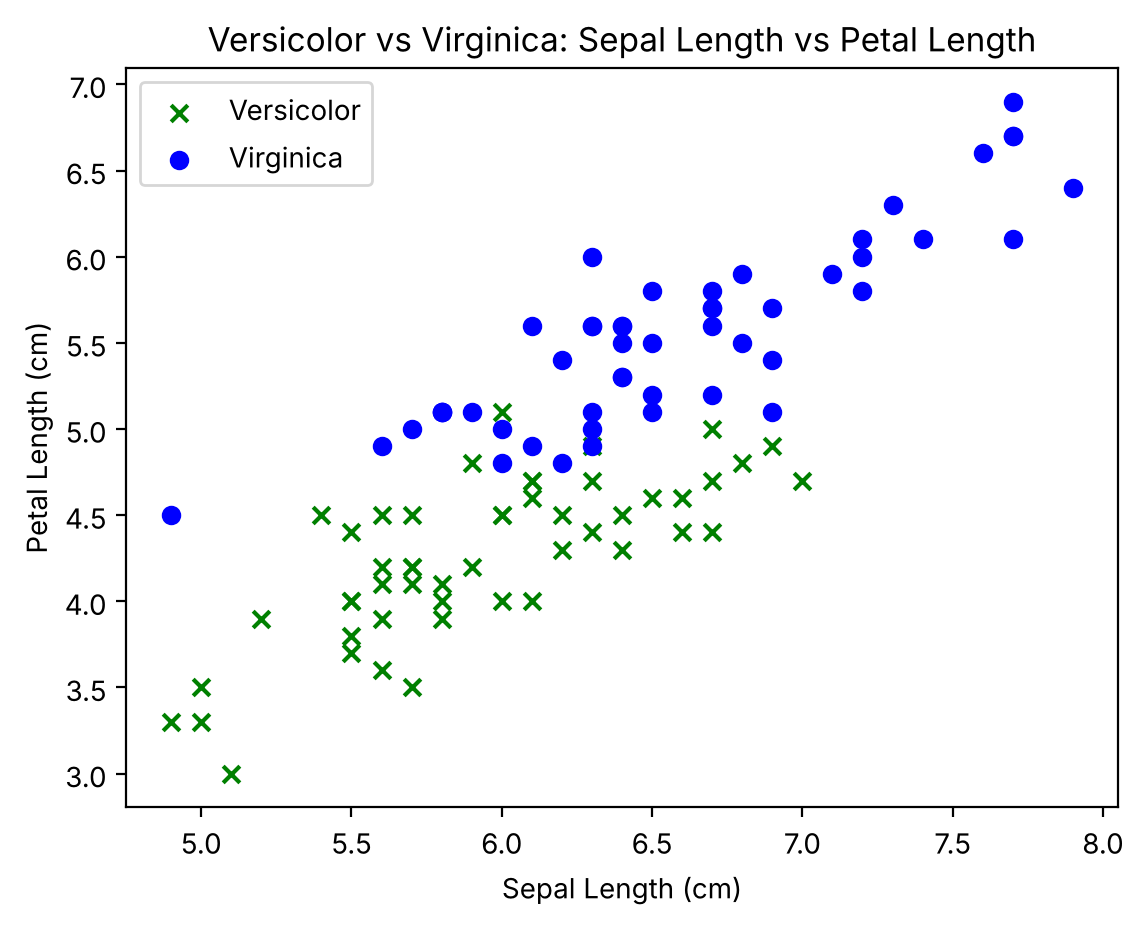

In [16]:
# Step 1: select Versicolor (rows 50-99) and Virginica (rows 100-149)
labels_t2 = iris_data.iloc[50:150, 4].values
y_t2 = np.where(labels_t2 == 1, -1, 1)          # Versicolor -> -1, Virginica -> +1
X_t2 = iris_data.iloc[50:150, [0, 2]].values     # sepal length, petal length

plt.scatter(X_t2[:50, 0], X_t2[:50, 1], color='green', marker='x', label='Versicolor')
plt.scatter(X_t2[50:, 0], X_t2[50:, 1], color='blue',  marker='o', label='Virginica')
plt.title("Versicolor vs Virginica: Sepal Length vs Petal Length")
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.legend(loc='upper left')
plt.show()

### Task 2 – Step 2: Pocket Algorithm implementation

Changes from PLA:
1. A **pocket** (`W_pocket`, `best_error`) stores the best weights seen so far. It is initialised with the starting weights and their error.
2. After **every** weight update, the error of the current `W` on the **whole dataset** is computed. If it is lower than `best_error`, the current `W` is copied into the pocket.
3. The current `W` keeps changing with the normal perceptron rule (it will oscillate because the data are not separable), but the pocket can only get better or stay the same.
4. For the report, the function records the current error and the pocket error after every iteration, plus a copy of `W` after each iteration, so the boundary at any phase can be plotted afterwards. It does **not** plot every iteration (100 plots would be unreadable).
5. It returns `W_pocket`, not the final `W`.

In [17]:
def misclassified(W, X, y):
    """Number of misclassified samples on the whole dataset."""
    return int(np.sum(predict(W, X) != y))


def fit_pocket(n_iter, X, y):
    W = np.zeros(1 + X.shape[1])
    W_pocket = W.copy()
    best_error = misclassified(W, X, y)
    best_iter = 0

    errors_current = []   # error of current W at end of each iteration
    errors_pocket = []    # error of pocket W at end of each iteration
    W_history = []        # current W at end of each iteration

    for i in range(n_iter):
        for xi, target in zip(X, y):
            if predict(W, xi) != target:
                W = W + target * np.append(1, xi)          # perceptron update
                err = misclassified(W, X, y)               # error on the whole dataset
                if err < best_error:                       # better than pocket? -> keep it
                    best_error = err
                    W_pocket = W.copy()
                    best_iter = i + 1
        errors_current.append(misclassified(W, X, y))
        errors_pocket.append(best_error)
        W_history.append(W.copy())

    return W_pocket, best_error, best_iter, errors_current, errors_pocket, W_history

### Task 2 – Step 3: Running the Pocket Algorithm (100 iterations)

In [18]:
n_iter_t2 = 100
W_pocket, best_error, best_iter, err_cur, err_pkt, W_hist = fit_pocket(n_iter_t2, X_t2, y_t2)

for i in [0, 9, 24, 49, best_iter - 1, 74, 99]:
    print(f"Iteration {i + 1:3d} | current W = {np.round(W_hist[i], 2)} | current errors = {err_cur[i]:2d} | pocket errors = {err_pkt[i]:2d}")

Iteration   1 | current W = [ 0.  -0.7  1.3] | current errors = 50 | pocket errors = 50
Iteration  10 | current W = [ 0. -7. 13.] | current errors = 50 | pocket errors = 50
Iteration  25 | current W = [  0.  -18.   31.6] | current errors = 50 | pocket errors = 49
Iteration  50 | current W = [  0.  -35.8  51. ] | current errors = 29 | pocket errors = 21
Iteration  68 | current W = [  0.  -40.3  67.2] | current errors = 49 | pocket errors = 10
Iteration  75 | current W = [ -1.  -45.2  70. ] | current errors = 47 | pocket errors = 10
Iteration 100 | current W = [ -1.  -59.9  90.4] | current errors = 44 | pocket errors = 10


### Task 2 – Step 4: Misclassification evolution and decision-boundary phases

The first plot compares the current PLA weights (which keep oscillating) with the pocket weights (which never get worse).
The three boundary plots show:
1. **Initialising** – iteration 1, the line is still far from the data split.
2. **Best** – the pocket weights, i.e. the lowest error found.
3. **Diverging** – a later iteration where the current PLA weights have moved away again and the error has gone back up.

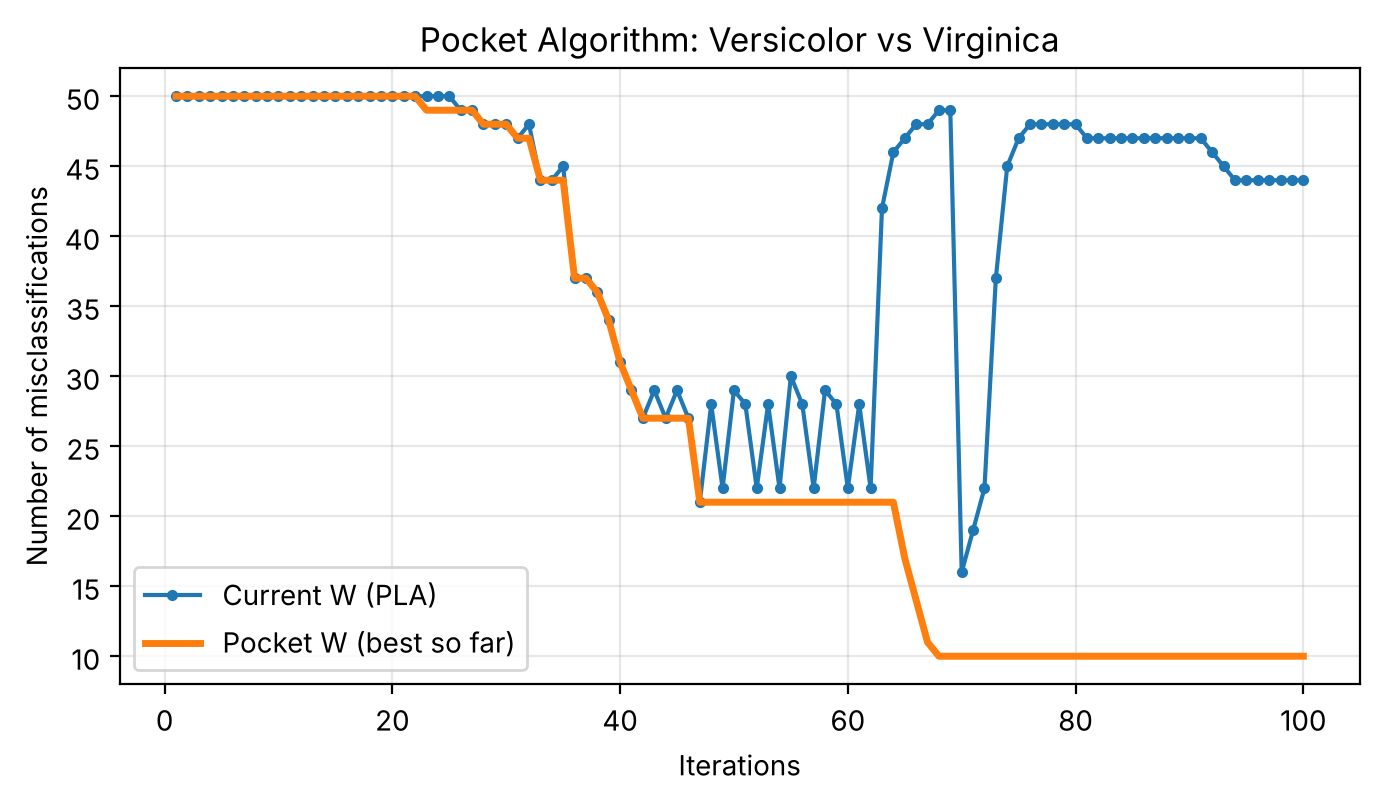

In [19]:
# Misclassifications over iterations: current W vs pocket W
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_iter_t2 + 1), err_cur, marker='.', label='Current W (PLA)')
plt.plot(range(1, n_iter_t2 + 1), err_pkt, linewidth=2.5, label='Pocket W (best so far)')
plt.xlabel('Iterations')
plt.ylabel('Number of misclassifications')
plt.title('Pocket Algorithm: Versicolor vs Virginica')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

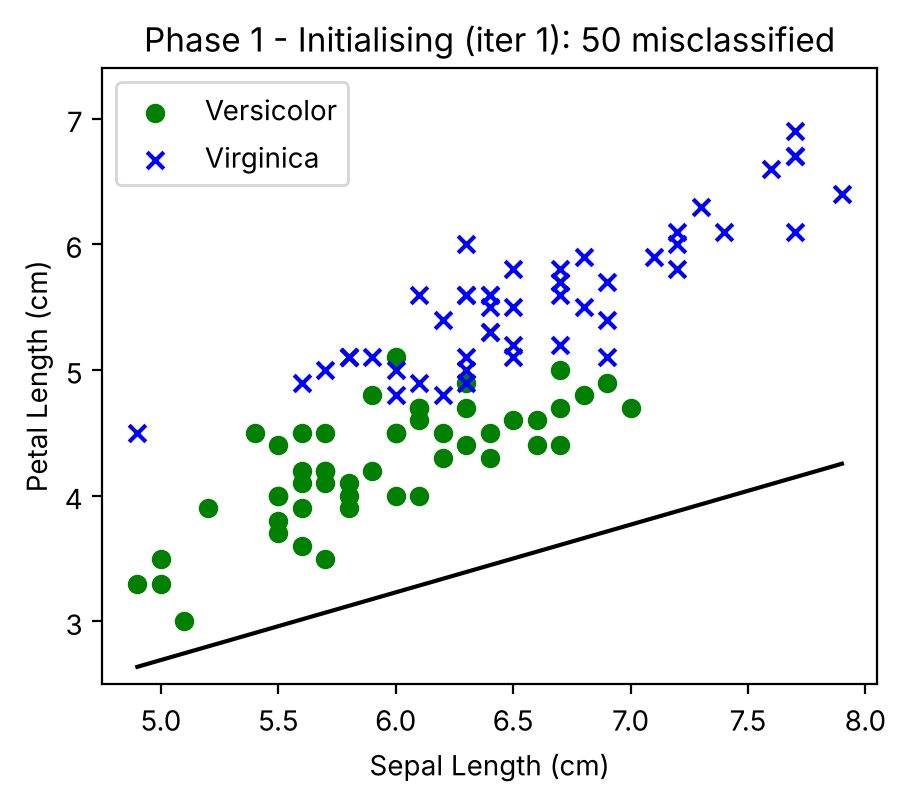

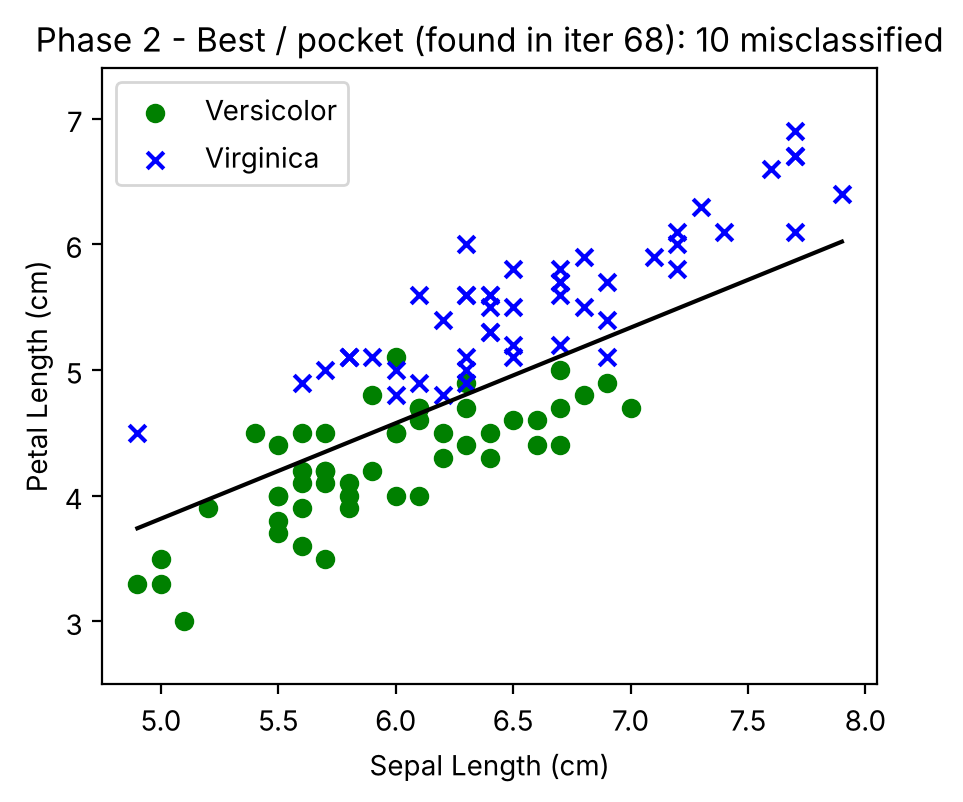

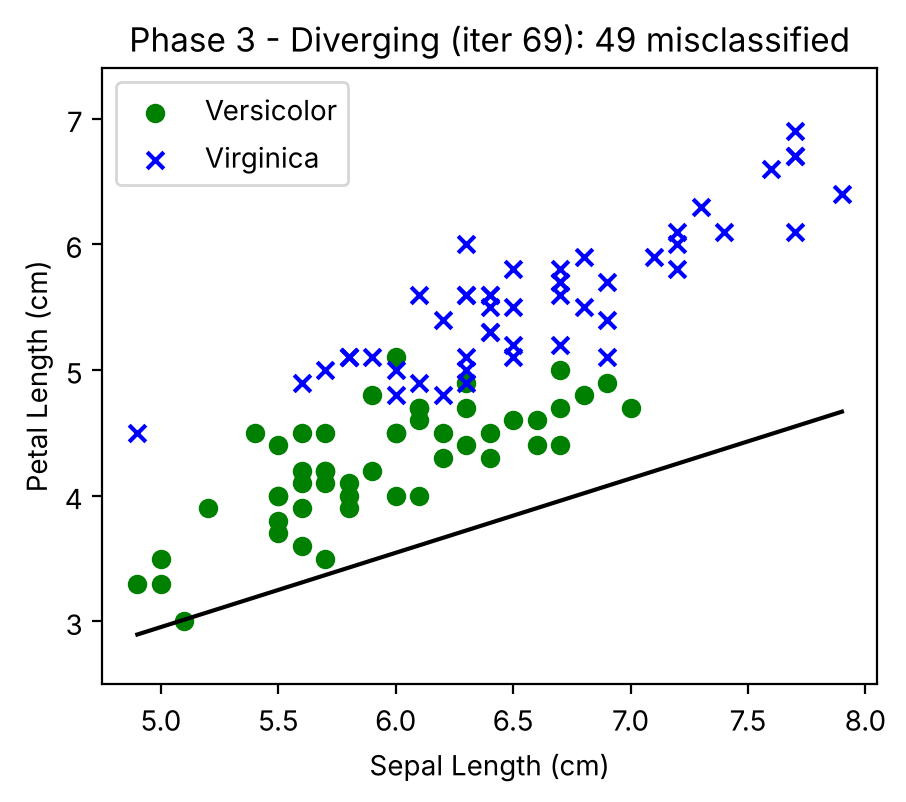

In [20]:
names_t2, colors_t2 = ('Versicolor', 'Virginica'), ('green', 'blue')

# Phase 1: initialising (iteration 1)
plot_boundary_general(W_hist[0], X_t2, names_t2, colors_t2,
                      title=f"Phase 1 - Initialising (iter 1): {err_cur[0]} misclassified")

# Phase 2: best iteration (pocket weights)
plot_boundary_general(W_pocket, X_t2, names_t2, colors_t2,
                      title=f"Phase 2 - Best / pocket (found in iter {best_iter}): {best_error} misclassified")

# Phase 3: diverging - the iteration after the best one where the current error is highest
after = np.arange(best_iter, n_iter_t2)                 # indices of iterations after best_iter
div_idx = after[np.argmax(np.array(err_cur)[after])]
plot_boundary_general(W_hist[div_idx], X_t2, names_t2, colors_t2,
                      title=f"Phase 3 - Diverging (iter {div_idx + 1}): {err_cur[div_idx]} misclassified")

### Task 2 – Step 5: Best weights

In [21]:
print("Best (pocket) weights W = [w0, w1, w2] =", W_pocket)
print("Found during iteration:", best_iter)
print(f"Misclassified: {best_error} / {len(y_t2)}  ->  accuracy = {100 * (1 - best_error / len(y_t2)):.1f} %")
print("For comparison, final PLA weights after 100 iterations:", W_hist[-1],
      "->", err_cur[-1], "misclassified")

Best (pocket) weights W = [w0, w1, w2] = [ -1.  -47.2  62.1]
Found during iteration: 68
Misclassified: 10 / 100  ->  accuracy = 90.0 %
For comparison, final PLA weights after 100 iterations: [ -1.  -59.9  90.4] -> 44 misclassified


### Task 2 – Step 6: Code modifications from PLA to Pocket

| Change | PLA (`fit`) | Pocket (`fit_pocket`) | Reason / impact |
|---|---|---|---|
| Memory | Only current `W` | Adds `W_pocket`, `best_error`, `best_iter` | Keeps the best solution, because the current `W` never settles on non-separable data |
| Error check | Once per iteration, only printed | After **every update**, on the whole dataset | A good `W` can appear mid-iteration and be overwritten by the next update; checking after each update catches it |
| Pocket update | – | `if err < best_error: W_pocket = W.copy()` | `.copy()` is needed, otherwise the pocket would just point to the changing array |
| Tracking | Error list only | Current error, pocket error and `W` history per iteration | Lets us plot the error evolution and pick the 3 phase plots after training |
| Plotting | Boundary plotted every iteration | Only the 3 selected phases | 100 plots would be unreadable |
| Output | Nothing returned | Returns `W_pocket` (not the last `W`) | The pocket is the useful classifier |

**Result:** the current PLA error swings between roughly 16 and 50 misclassifications and finishes at 44 after 100 iterations. The pocket keeps the best weights, **W = [-1.0, -47.2, 62.1]**, found in iteration 68, with **10 / 100 misclassified (90 % accuracy)**. The pocket error curve can only fall or stay flat, which shows why the Pocket Algorithm is needed when the data are not linearly separable.

*Note:* the features are not scaled and the weights start at zero, so PLA takes many iterations to get going (the error stays at 50 for about 20 iterations). Standardising the features or using a learning rate would probably speed this up, but the tutorial set-up is kept here so the results stay comparable.